# 07_track2_volume: Track 2, forecasting ticket volume
Goal from the brief: forecast incident volume quarterly and annually, so ABC Tech can plan resources and technology. Aggregates only: no ticket rows are printed. Needs data/processed/itsm_clean.pkl and statsmodels.

**Contents**
- Section 1: setup (libraries and settings).
- Sections 2 to 7: the data as a daily time series, its trend and weekly seasonality, stationarity (ADF tests on the original, first-differenced and weekly-differenced series), and the train and test split.
- Sections 8 to 13: Holt-Winters, ARIMA and SARIMA, each forecasting the test period once; SARIMA residual diagnostics (10c); comparison with MAE, RMSE, MAPE and WAPE (12 and 12b).
- Sections 14 to 16: the monthly run-rate; the final SARIMA model trained on all observations and its quarterly and annual forecast (15); history and forecast plotted quarterly and annually (16).
- Section 17: a rolling 4-week validation.
- Section 18: the same forecast for **incidents only**, as the brief words Objective 2 (18a series and backtest, 18b final model and forecast, 18c plots).
- Section 19: the final conclusion with the planning estimate for management.
- Appendix A: short-term evaluation (rolling 7-day forecasts from 38 origins, a rule set in advance, and checks on earlier months). Supporting evidence; not needed for the quarterly objective.

**Headline:** no model reliably beats repeating last week. **Incidents** (about 81% of tickets): about 18,500 to 19,100 per quarter and about 75,000 over the next 12 months at the October to February rate, or about 68,000 if the early-March level continues (section 18). **All tickets**, the service desk's full workload, from the working-day run-rate: about 23,000 to 23,700 tickets per quarter and about 94,000 over the next 12 months at the October to February rate, or about 20,200 to 20,800 per quarter (about 82,000 a year) if the lower early-March level continues. Allow about ±10% (measured on 4-week totals); quarterly and annual accuracy cannot be validated with 5.5 months of data.

## 1. Setup: libraries and settings

In [1]:
# Standard library
import os
import sys
import warnings

# Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import MSTL, seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

# Project modules
sys.path.append("../src")
from project_config import CUT, START, TEST_START

# Settings
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
os.makedirs("../reports/figures", exist_ok=True)

<details>
<summary><b>Code notes, line by line</b></summary>

- `import os, sys, warnings` : Paths, the import path, and warning control.
- `matplotlib, numpy, pandas` : Plots, arrays and data frames.
- `from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error` : Standard error measures, used in section 12b.
- `acorr_ljungbox` : Ljung-Box test: is there pattern left in the residuals?
- `ARIMA / ExponentialSmoothing / SARIMAX` : The three forecasting models (ExponentialSmoothing is Holt-Winters).
- `MSTL, seasonal_decompose` : Split a series into trend, seasonal cycles and remainder.
- `adfuller` : Augmented Dickey-Fuller test for stationarity.
- `from project_config import CUT, START, TEST_START` : Shared window and split dates.
- `warnings.filterwarnings("ignore")` : Hides the many convergence warnings printed during the order search (convergence is checked explicitly in 10b).
- `os.makedirs("../reports/figures", exist_ok=True)` : Folder for saved figures.

</details>

## 2. Load and inspect the dataset

In [2]:
df = pd.read_pickle("../data/processed/itsm_clean.pkl")
print("Rows, columns:", df.shape)
print("Open_Time range :", df["Open_Time"].min(), "to", df["Open_Time"].max())
print("Close_Time range:", df["Close_Time"].min(), "to", df["Close_Time"].max())

Rows, columns: (46606, 26)
Open_Time range : 2012-02-05 13:32:00 to 2014-03-31 17:24:00
Close_Time range: 2013-10-01 06:45:00 to 2014-03-31 22:47:00


<details>
<summary><b>Code notes, line by line</b></summary>

- `df = pd.read_pickle(...)` : The clean checkpoint.
- `df["Open_Time"].min(), max() / Close_Time` : Date ranges: opened from 2012 but closed only from October 2013, which shows the close-date cut.

</details>

## 3. Convert the data into a time series
First the monthly series the template asks for, then the daily series used for modelling.

In [3]:
# Monthly counts of opened tickets across the whole extract
monthly_all = df.set_index("Open_Time").resample("MS").size().rename("tickets")
print("Table 3a. Tickets opened per month, June 2013 onward")
display(monthly_all.loc["2013-06":].to_frame().T)

# Clean window used by every track: opened 1 Oct 2013 to 16 Mar 2014
w = df[(df["Open_Time"] >= START) & (df["Open_Time"] < CUT)]
daily = w.set_index("Open_Time").resample("D").size().rename("tickets").astype(float)
monthly = daily.resample("MS").sum()

print("Table 3b. The monthly and daily series in the window")
print(pd.DataFrame({"Points": [len(monthly), len(daily)],
                    "From": [monthly.index.min().date(), daily.index.min().date()],
                    "To": [monthly.index.max().date(), daily.index.max().date()]},
                   index=["Monthly series (window)", "Daily series (window)"]))
print("Daily frequency:", daily.index.freq, "| missing days:",
      len(pd.date_range(daily.index.min(), daily.index.max(), freq="D")) - len(daily),
      "| days with zero tickets:", int((daily == 0).sum()))

Table 3a. Tickets opened per month, June 2013 onward


Open_Time,2013-06-01,2013-07-01,2013-08-01,2013-09-01,2013-10-01,2013-11-01,2013-12-01,2014-01-01,2014-02-01,2014-03-01
tickets,36,73,93,857,8606,8128,6743,8270,7377,6332


Table 3b. The monthly and daily series in the window
                         Points        From          To
Monthly series (window)       6  2013-10-01  2014-03-01
Daily series (window)       167  2013-10-01  2014-03-16
Daily frequency: <Day> | missing days: 0 | days with zero tickets: 2


<details>
<summary><b>Code notes, line by line</b></summary>

- `df.set_index("Open_Time").resample("MS").size()` : Tickets opened per month across the whole extract.
- `display(monthly_all.loc["2013-06":].to_frame().T)` : Months from June 2013 as one row.
- `w = df[(Open_Time >= START) & (Open_Time < CUT)]` : The 167-day modelling window.
- `daily = w.set_index("Open_Time").resample("D").size()...astype(float)` : Tickets opened per calendar day; days with no tickets become 0 (resample fills every day).
- `monthly = daily.resample("MS").sum()` : The same window as monthly totals.
- `print(pd.DataFrame({"Points": ..., "From": ..., "To": ...}))` : Number of points and dates of both series.
- `daily.index.freq; missing days; (daily == 0).sum()` : Checks the daily series is regular, complete and how many days are zero.

</details>

### Why 167 days
- **The extract is cut by close date.** It holds every ticket *closed* between 1 October 2013 and 31 March 2014 (182 days); a ticket appears only if it closed in that window.
- **Before 1 October there is only the backlog.** Tickets opened earlier appear only if they were still open on 1 October, so they are the slow ones: 857 in September, 93 in August, 73 in July, against 6,000 to 8,600 a month from October. Only 1 of the 1,114 labelled backlog tickets is high priority (0.09%), against 1.58% from October, so these months do not show real volume and are left out.
- **After 16 March the counts are too low.** Tickets opened in late March and still open on 31 March are missing. The share of tickets open longer than 72 hours falls from a steady 24 to 27% to 19.2%, 9.9% and 0.0% in the last three weeks, so the 3,152 tickets opened from 17 March are left out.
- **What is left:** tickets opened from 1 October 2013 to 16 March 2014, 167 days and 42,304 tickets, with every day's count complete. All four tracks use this window (decided in 04_eda, section 13, which shows this in one figure). More history needs a new extract selected by open date, covering two to three years.

### Why the models use the daily series
- The extract holds tickets **closed** between 1 October 2013 and 31 March 2014. Months before October contain only the slow backlog (survivorship), and tickets opened in late March and still open on 31 March are missing.
- That leaves **5 complete months** (October to February) plus half of March. Holt-Winters, ARIMA and SARIMA cannot be fitted or tested on 5 monthly points, and yearly seasonality needs at least 24 months.
- So the models are fitted on the **167 daily counts** (weekly seasonality, period 7). Their daily forecasts are then summed to months, quarters and a year.

## 4. Plot the original time series

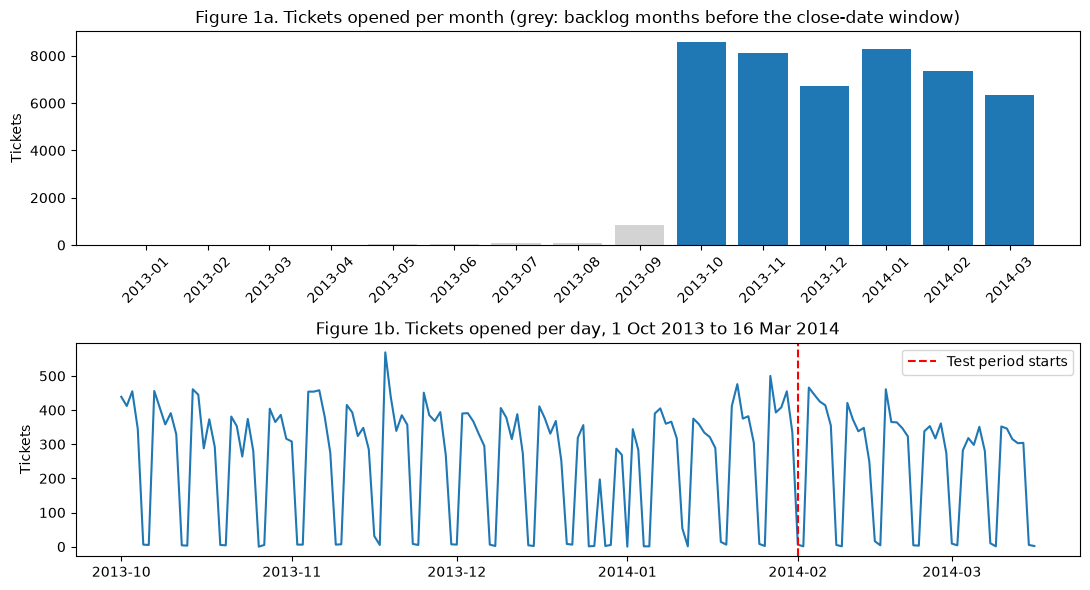

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
m = monthly_all.loc["2013-01":]
axes[0].bar(m.index.strftime("%Y-%m"), m.values,
            color=["tab:blue" if d >= pd.Timestamp(START) else "lightgrey" for d in m.index])
axes[0].set_title("Figure 1a. Tickets opened per month (grey: backlog months before the close-date window)")
axes[0].set_ylabel("Tickets")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(daily.index, daily.values)
axes[1].axvline(pd.Timestamp(TEST_START), color="red", linestyle="--", label="Test period starts")
axes[1].set_title("Figure 1b. Tickets opened per day, 1 Oct 2013 to 16 Mar 2014")
axes[1].set_ylabel("Tickets")
axes[1].legend()
fig.tight_layout()
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `fig, axes = plt.subplots(2, 1, ...)` : Two panels.
- `axes[0].bar(..., color=[blue if d >= START else lightgrey ...])` : Monthly bars; backlog months before the window in grey.
- `axes[1].plot(daily.index, daily.values)` : Daily counts in the window.
- `axes[1].axvline(TEST_START, ...)` : Red dashed line where the test period starts.

</details>

**Result.** Figure 1a: opened tickets per month jump from under 900 before October 2013 (grey bars, the backlog only) to 6,700 to 8,600 a month from October (Table 3a). Figure 1b: the daily series repeats a sharp weekly rhythm through the whole window, with a dip over Christmas and New Year and no clear trend. Table 3b confirms 167 complete days, with only 2 days that have no tickets.

## 5. Trend and seasonality

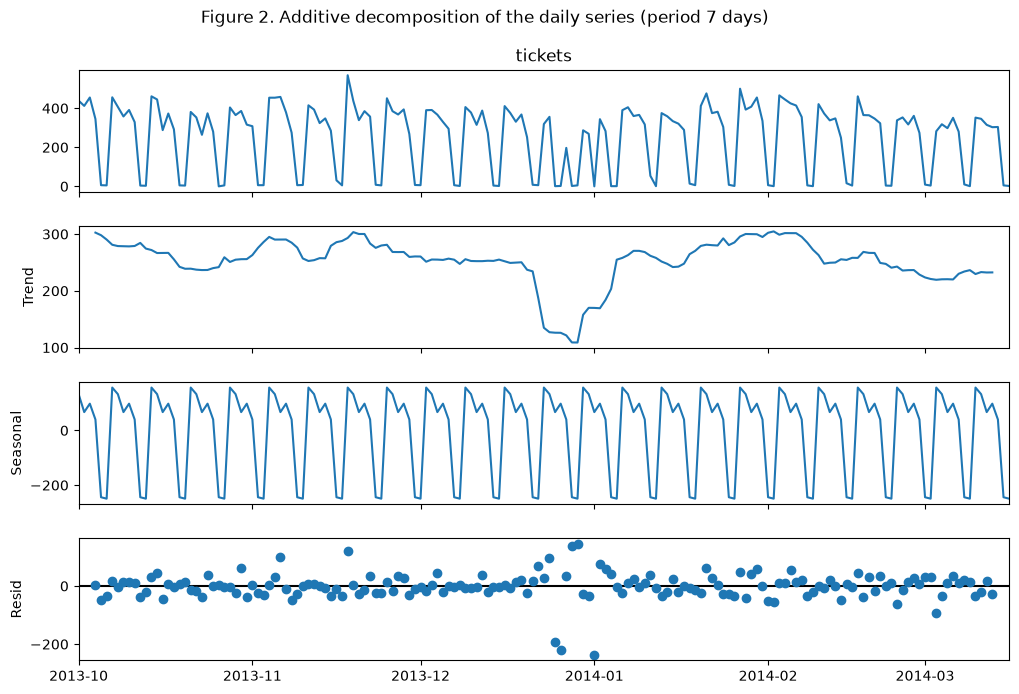

Table 5a. Average tickets per day of the week


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
Average tickets,409.0,387.0,323.0,354.0,295.0,9.0,4.0


Weekly seasonal swing (max minus min of the seasonal component): 406.0 tickets


In [5]:
dec = seasonal_decompose(daily, model="additive", period=7)
fig = dec.plot()
fig.set_size_inches(11, 7)
fig.suptitle("Figure 2. Additive decomposition of the daily series (period 7 days)", y=1.01)
plt.show()

wd = daily.groupby(daily.index.day_of_week).mean().round(0)
wd.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Table 5a. Average tickets per day of the week")
display(wd.to_frame("Average tickets").T)
print("Weekly seasonal swing (max minus min of the seasonal component):",
      round(dec.seasonal.max() - dec.seasonal.min(), 1), "tickets")

<details>
<summary><b>Code notes, line by line</b></summary>

- `seasonal_decompose(daily, model="additive", period=7)` : Splits the daily series into trend + weekly pattern + remainder (additive: the parts add up).
- `dec.plot()` : Four panels: observed, trend, seasonal, residual.
- `daily.groupby(daily.index.day_of_week).mean()` : Average tickets per weekday (0 = Monday).
- `dec.seasonal.max() - dec.seasonal.min()` : Size of the weekly swing in tickets.

</details>

**Result.** In Figure 2 the trend panel is roughly flat apart from the Christmas dip, and the seasonal panel repeats one weekly shape with a swing of 406 tickets from top to bottom. Table 5a gives the shape: weekdays average 295 (Friday) to 409 (Monday) tickets, Saturday 9 and Sunday 4. Any forecasting model must reproduce this weekend drop.

### 5b. Multiple seasonal decomposition (weekly and monthly)
MSTL separates a weekly (7-day) and a monthly (30-day) cycle. A yearly cycle cannot be estimated from 167 days.

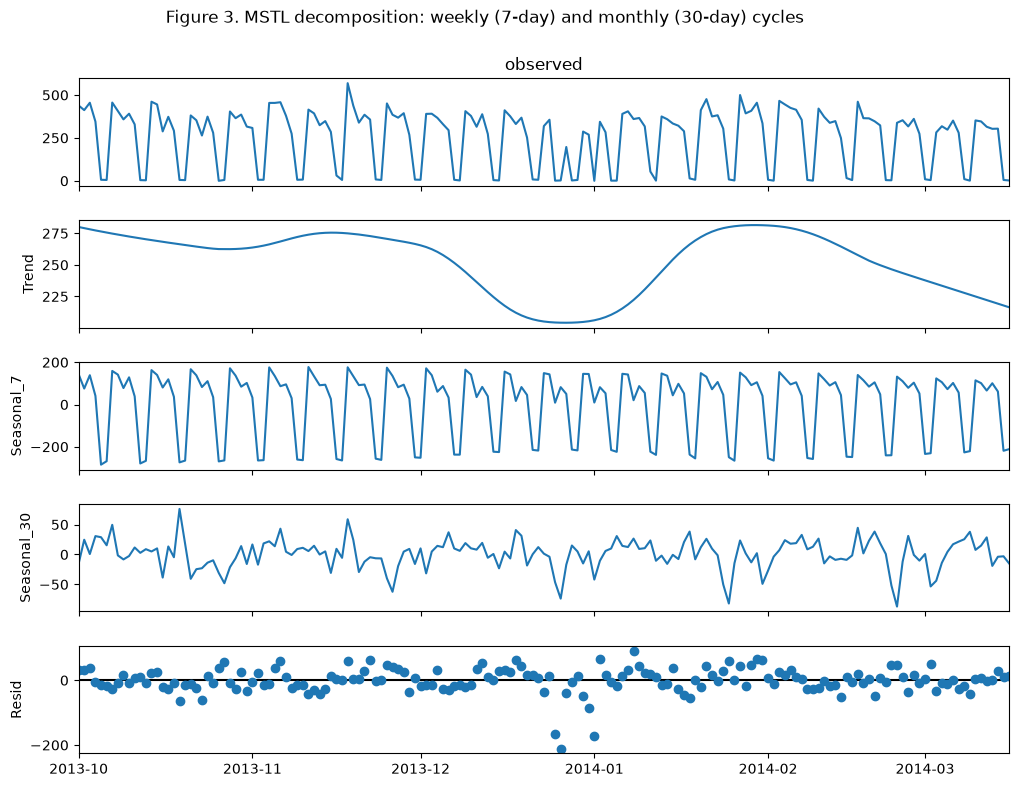

Table 5b. Seasonal strength (MSTL)
Seasonal strength, weekly (7 days): 0.95
Seasonal strength, monthly (30 days): 0.31


In [6]:
mstl = MSTL(daily, periods=(7, 30)).fit()
fig = mstl.plot()
fig.set_size_inches(11, 8)
fig.suptitle("Figure 3. MSTL decomposition: weekly (7-day) and monthly (30-day) cycles", y=1.01)
plt.show()

def strength(seasonal, resid):
    """Share of variation the seasonal part explains beyond noise: near 1 strong, near 0 none."""
    return max(0.0, 1 - resid.var() / (seasonal + resid).var())

print("Table 5b. Seasonal strength (MSTL)")
print("Seasonal strength, weekly (7 days):", round(strength(mstl.seasonal["seasonal_7"], mstl.resid), 2))
print("Seasonal strength, monthly (30 days):", round(strength(mstl.seasonal["seasonal_30"], mstl.resid), 2))

<details>
<summary><b>Code notes, line by line</b></summary>

- `MSTL(daily, periods=(7, 30)).fit()` : Decomposition with two seasonal cycles at once: weekly and roughly monthly.
- `mstl.plot()` : Trend, both seasonal parts and the remainder.
- `def strength(seasonal, resid):` : Seasonal strength = 1 - var(remainder) / var(seasonal + remainder): near 1 means the cycle is strong.
- `print(... seasonal_7 ...); print(... seasonal_30 ...)` : Strength of each cycle.

</details>

**Result.** The weekly cycle dominates: seasonal strength 0.95 (Table 5b), and the 7-day panel of Figure 3 repeats the same shape all through the window. The 30-day component is moderate (0.31) but irregular, so 5c checks whether there is a real within-month pattern.

### 5c. Checking the monthly pattern and the late trend

In [7]:
wd = daily[daily.index.day_of_week < 5]
wd = wd[~((wd.index >= "2013-12-17") & (wd.index <= "2014-01-08"))]     # leave out the holiday window

bucket = pd.cut(wd.index.day, [0, 5, 10, 15, 20, 25, 31],
                labels=["1-5", "6-10", "11-15", "16-20", "21-25", "26-31"])
print("Table 5c-1. Average weekday tickets by day of the month (holiday window excluded)")
display(wd.groupby(bucket, observed=True).agg(["mean", "count"]).round(0))

print("Table 5c-2. Average weekday tickets by month (holiday window excluded; March is 1 to 16 only)")
display(wd.groupby(wd.index.to_period("M")).agg(["mean", "count"]).round(0))

Table 5c-1. Average weekday tickets by day of the month (holiday window excluded)


,mean,count
1-5,387.0,17
6-10,370.0,18
11-15,346.0,22
16-20,376.0,14
21-25,360.0,15
26-31,371.0,16


Table 5c-2. Average weekday tickets by month (holiday window excluded; March is 1 to 16 only)


,mean,count
Open_Time,,
2013-10,373.0,23
2013-11,383.0,21
2013-12,359.0,11
2014-01,377.0,17
2014-02,367.0,20
2014-03,315.0,10


<details>
<summary><b>Code notes, line by line</b></summary>

- `wd = daily[daily.index.day_of_week < 5]` : Weekdays only (weekends would hide any monthly pattern).
- `wd = wd[~("2013-12-17" <= date <= "2014-01-08")]` : Leaves out the Christmas and New Year window.
- `pd.cut(wd.index.day, [0, 5, 10, ...], labels=[...])` : Groups days of the month into six buckets.
- `wd.groupby(bucket).agg(["mean", "count"])` : Table 5c-1: average weekday tickets per bucket; a month-end peak would show here.
- `wd.groupby(wd.index.to_period("M")).agg(...)` : Table 5c-2: average weekday tickets per month, to see the March level.

</details>

**Result.** No within-month pattern: weekday averages by day of the month range from 346 to 387, within about ±6% of the overall average, with no month-end peak (Table 5c-1); the 30-day MSTL component reflects noise and the holiday window. Outside the holiday window, October to February run at 359 to 383 tickets per weekday, but 1 to 16 March runs at 315, about 15% lower (Table 5c-2). Closed tickets, which are complete in this extract, also fell in March (345 per weekday against 377 in February), so the drop is probably real and not only an effect of the end-of-window cut.

## 6. Stationarity: Augmented Dickey-Fuller test
ARIMA-type models need a stationary series: constant mean and variance, and no trend. The ADF test checks this.

**Hypotheses**
- **Null hypothesis:** the series has a unit root (it is non-stationary).
- **Alternative hypothesis:** the series is stationary.

**Decision rule:** p-value below 0.05: reject the null, the series is stationary. p-value 0.05 or above: fail to reject, the series is non-stationary.

The original series is tested first (6b), then after a first difference (6c) and after a weekly difference (6d); 6e collects all versions in one table.

### 6a. A reusable ADF-test function

In [8]:
def adf_test(series, title="Series"):
    """Augmented Dickey-Fuller test, printed with its decision at the 5% level."""
    result = adfuller(series.dropna(), autolag="AIC")
    print(title)
    print(f"ADF statistic: {result[0]:.3f}")
    print(f"p-value: {result[1]:.4f}")
    print("Number of lags used:", result[2])
    print("Number of observations:", result[3])
    print("Critical values:", {k: round(v, 3) for k, v in result[4].items()})
    if result[1] < 0.05:
        print("Inference: reject the null hypothesis. The series is stationary.\n")
    else:
        print("Inference: fail to reject the null hypothesis. The series is non-stationary.\n")

<details>
<summary><b>Code notes, line by line</b></summary>

- `def adf_test(series, title="Series"):` : A reusable function, so every version of the series is tested and reported the same way.
- `result = adfuller(series.dropna(), autolag="AIC")` : Runs the Augmented Dickey-Fuller test; dropna removes the empty first values a difference creates; AIC picks the number of lags.
- `result[0]` : The ADF statistic: the more negative, the stronger the evidence of stationarity.
- `result[1]` : The p-value.
- `result[2], result[3]` : Lags used by the test, and observations used.
- `result[4]` : Critical values at 1%, 5% and 10%: a statistic below a critical value rejects the null at that level.
- `if result[1] < 0.05: ... else: ...` : Prints the decision at the 5% level.

</details>

### 6b. Test the original series for stationarity

In [9]:
adf_test(daily, f"Table 6b. ADF test: original daily series ({daily.index[0].date()} to {daily.index[-1].date()})")

Table 6b. ADF test: original daily series (2013-10-01 to 2014-03-16)
ADF statistic: -2.288
p-value: 0.1760
Number of lags used: 13
Number of observations: 153
Critical values: {'1%': np.float64(-3.474), '5%': np.float64(-2.881), '10%': np.float64(-2.577)}
Inference: fail to reject the null hypothesis. The series is non-stationary.



<details>
<summary><b>Code notes, line by line</b></summary>

- `adf_test(daily, f"... {daily.index[0].date()} to {daily.index[-1].date()}")` : Tests the original daily counts (all 167 days); the title shows the dates tested.

</details>

**Inference.** ADF statistic -2.29 and p-value 0.18, above 0.05 (Table 6b): the null hypothesis is not rejected, so the original daily series is **non-stationary**. The statistic is above even the 10% critical value (-2.58). Its level moves (the Christmas dip and the lower early-March level in Figure 1b) and the weekly cycle repeats every 7 days (Figure 2); both must be handled before modelling.

### 6c. First-order differencing
`daily.diff()` subtracts yesterday's count from today's. A first difference removes changes in level (trend).

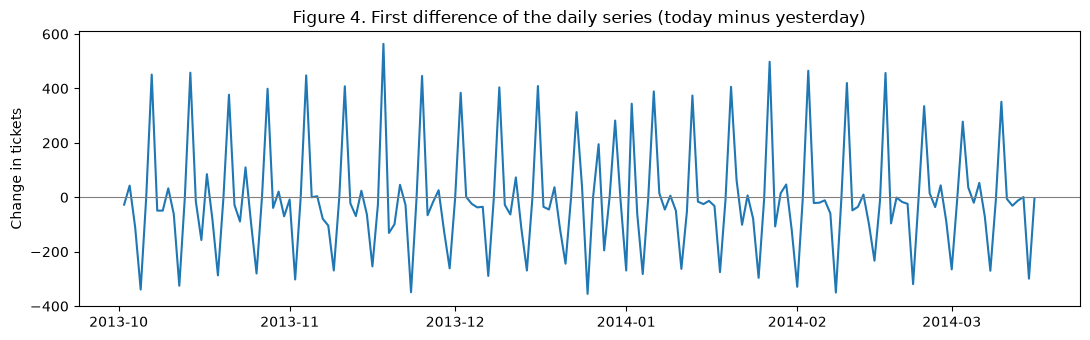

Table 6c. ADF test: first-differenced series
ADF statistic: -5.571
p-value: 0.0000
Number of lags used: 12
Number of observations: 153
Critical values: {'1%': np.float64(-3.474), '5%': np.float64(-2.881), '10%': np.float64(-2.577)}
Inference: reject the null hypothesis. The series is stationary.



In [10]:
first_diff = daily.diff()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(first_diff.index, first_diff.values)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_title("Figure 4. First difference of the daily series (today minus yesterday)")
ax.set_ylabel("Change in tickets")
fig.tight_layout()
plt.show()

adf_test(first_diff, "Table 6c. ADF test: first-differenced series")

<details>
<summary><b>Code notes, line by line</b></summary>

- `first_diff = daily.diff()` : Today's count minus yesterday's; the first day becomes empty.
- `ax.plot(...); ax.axhline(0, ...)` : Plots the differenced series around a zero line.
- `adf_test(first_diff, ...)` : Tests whether one regular difference is enough.

</details>

**Inference.** ADF statistic -5.57, p-value below 0.001 (Table 6c): the first-differenced series is **stationary**, so one regular difference is enough for ARIMA (**d = 1**). Figure 4 still shows the weekly rhythm (large falls into each weekend and rises every Monday): a non-seasonal ARIMA has no term for it.

### 6d. Seasonal (weekly) differencing
`daily.diff(7)` subtracts the count on the same weekday a week earlier. Lag 7 is used because the data are daily and the pattern repeats every week (the AirPassengers example uses 12 for monthly data with a yearly pattern). The combined first and weekly difference, as used in that example, is also tested.

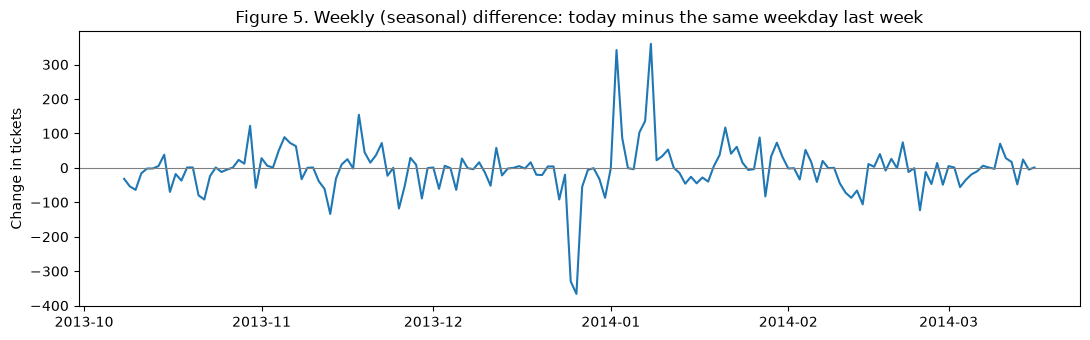

Table 6d-1. ADF test: weekly-differenced series (lag 7)
ADF statistic: -4.653
p-value: 0.0001
Number of lags used: 13
Number of observations: 146
Critical values: {'1%': np.float64(-3.476), '5%': np.float64(-2.882), '10%': np.float64(-2.577)}
Inference: reject the null hypothesis. The series is stationary.

Table 6d-2. ADF test: first and weekly difference together
ADF statistic: -5.038
p-value: 0.0000
Number of lags used: 13
Number of observations: 145
Critical values: {'1%': np.float64(-3.476), '5%': np.float64(-2.882), '10%': np.float64(-2.578)}
Inference: reject the null hypothesis. The series is stationary.



In [11]:
weekly_diff = daily.diff(7)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(weekly_diff.index, weekly_diff.values)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_title("Figure 5. Weekly (seasonal) difference: today minus the same weekday last week")
ax.set_ylabel("Change in tickets")
fig.tight_layout()
plt.show()

adf_test(weekly_diff, "Table 6d-1. ADF test: weekly-differenced series (lag 7)")
adf_test(daily.diff().diff(7), "Table 6d-2. ADF test: first and weekly difference together")

<details>
<summary><b>Code notes, line by line</b></summary>

- `weekly_diff = daily.diff(7)` : Today's count minus the same weekday a week earlier; the first 7 days become empty.
- `ax.plot(...)` : Plots the weekly-differenced series.
- `adf_test(weekly_diff, ...)` : Tests whether the weekly difference alone makes the series stationary.
- `adf_test(daily.diff().diff(7), ...)` : Tests both differences together, as in the AirPassengers example (d = 1 and D = 1).

</details>

**Inference.** The weekly difference alone gives ADF statistic -4.65 and p-value 0.0001 (Table 6d-1): the series is **stationary**. In Figure 5 the weekend drops cancel out (each Saturday is compared with the previous Saturday), and what remains is mainly the Christmas and New Year disturbance. So SARIMA needs one seasonal difference (**D = 1, s = 7**) and no regular difference (**d = 0**); section 7 confirms this on the training data only. The combined first and weekly difference is also stationary (ADF -5.04, p < 0.001; Table 6d-2) but is not needed: differencing more than necessary (over-differencing) adds noise to the model.

### 6e. All versions in one table

In [12]:
def adf_row(name, s):
    stat, p, lags, nobs, crit, _ = adfuller(s.dropna(), autolag="AIC")
    return {"Series": name, "ADF statistic": round(stat, 3), "p-value": round(p, 4),
            "Lags used": lags, "Observations": nobs, "Stationary at 5%": bool(p < 0.05)}

log_daily = np.log1p(daily)          # log(1 + x): the series has days with zero tickets
adf_table = pd.DataFrame([adf_row("Original", daily),
                          adf_row("Log", log_daily),
                          adf_row("First difference", daily.diff()),
                          adf_row("Weekly (seasonal) difference, lag 7", daily.diff(7)),
                          adf_row("First + weekly difference", daily.diff().diff(7)),
                          adf_row("Log + weekly difference", log_daily.diff(7))]).set_index("Series")
print("Table 6e. ADF test on every version of the series")
display(adf_table)

Table 6e. ADF test on every version of the series


,ADF statistic,p-value,Lags used,Observations,Stationary at 5%
Series,,,,,
Original,-2.288,0.1760,13,153,False
Log,-2.517,0.1114,13,153,False
First difference,-5.571,0.0000,12,153,True
"Weekly (seasonal) difference, lag 7",-4.653,0.0001,13,146,True
First + weekly difference,-5.038,0.0000,13,145,True
Log + weekly difference,-4.574,0.0001,13,146,True


<details>
<summary><b>Code notes, line by line</b></summary>

- `def adf_row(name, s):` : Same test as adf_test, returned as one table row instead of printed.
- `"Stationary at 5%": bool(p < 0.05)` : The decision for each row.
- `log_daily = np.log1p(daily)` : log(1 + x), safe for days with zero tickets; shown for completeness.
- `adf_row("Original", ...), ("Log", ...), ("First difference", ...), ("Weekly ...", ...), ("First + weekly ...", ...), ("Log + weekly ...", ...)` : Every version tested, in one table.
- `display(adf_table)` : Table 6e.

</details>

### Transformation and differencing decisions
- **Log transform: not used for the models.** The weekly swing stays about the same size across the window (Figure 2), which suits additive models, and log(1 + x) distorts the near-zero weekend days. On its own the log series is still non-stationary (p = 0.11, Table 6e); it is shown for completeness.
- **Differencing is handled inside the models, not applied by hand.** SARIMA always takes a weekly difference (D = 1, period 7). ARIMA's and SARIMA's ordinary difference `d` is set from the ADF test on the **training data only** (section 7): 0 if that series is stationary at 5%, otherwise 1. Holt-Winters models level, trend and weekly season directly.

### SARIMA interpretation
- `d = 0`: no regular difference (the weekly difference alone is enough, Table 6e).
- `D = 1`: one seasonal difference.
- `s = 7`: the seasonal period, one week of daily data.

## 7. Train and test split
Same split as the other tracks: train on 1 October 2013 to 31 January 2014, test on 1 February to 16 March 2014. Each model forecasts the whole test period in one go from 31 January. A seasonal naive forecast (repeat the last training week) is added as a reference.



In [13]:
train = daily[daily.index < TEST_START]
test = daily[daily.index >= TEST_START]
print("Table 7. Train and test split, and the differencing orders")
print(f"Train: {len(train)} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test : {len(test)} days ({test.index.min().date()} to {test.index.max().date()})")

# Reference: seasonal naive, repeating the last training week
assert train.index[-7].day_of_week == test.index[0].day_of_week
fc_naive = pd.Series(np.resize(train.iloc[-7:].to_numpy(), len(test)), index=test.index)

# Differencing orders from the ADF test on the training data only
d_arima = 0 if adfuller(train, autolag="AIC")[1] < 0.05 else 1
d_sarima = 0 if adfuller(train.diff(7).dropna(), autolag="AIC")[1] < 0.05 else 1
print("ARIMA d:", d_arima, "| SARIMA d:", d_sarima, "(SARIMA also takes D = 1 with period 7)")

Table 7. Train and test split, and the differencing orders
Train: 123 days (2013-10-01 to 2014-01-31)
Test : 44 days (2014-02-01 to 2014-03-16)
ARIMA d: 1 | SARIMA d: 0 (SARIMA also takes D = 1 with period 7)


<details>
<summary><b>Code notes, line by line</b></summary>

- `train = daily[< TEST_START]; test = daily[>= TEST_START]` : 123 training days and 44 test days.
- `assert train.index[-7].day_of_week == test.index[0].day_of_week` : Check that repeating the last training week lines up with the test weekdays.
- `fc_naive = pd.Series(np.resize(train.iloc[-7:], len(test)), index=test.index)` : Seasonal naive baseline: the last training week repeated across the test period.
- `d_arima = 0 if adfuller(train)[1] < 0.05 else 1` : ARIMA's difference order from the ADF test on training data only.
- `d_sarima = 0 if adfuller(train.diff(7).dropna())[1] < 0.05 else 1` : SARIMA's extra difference, tested after its weekly difference.

</details>

**Result.** 123 training days and 44 test days (Table 7). The non-seasonal difference d was set from the ADF test on the training data: d = 1 for ARIMA (the raw series is not stationary) and d = 0 for SARIMA (stationary after its weekly difference, D = 1).

## 8. Holt-Winters
Additive weekly season (period 7) with an additive damped trend, so the trend flattens out over long horizons.

In [14]:
def fit_hw(s):
    return ExponentialSmoothing(s, trend="add", damped_trend=True, seasonal="add",
                                seasonal_periods=7, initialization_method="estimated").fit()

hw_res = fit_hw(train)
fc_hw = pd.Series(np.clip(np.asarray(hw_res.forecast(len(test))), 0, None), index=test.index)
print("Table 8. Holt-Winters fitted | smoothing level, trend, season:",
      [round(hw_res.params[k], 3) for k in ["smoothing_level", "smoothing_trend", "smoothing_seasonal"]],
      "| damping:", round(hw_res.params["damping_trend"], 3))

Table 8. Holt-Winters fitted | smoothing level, trend, season: [np.float64(0.306), np.float64(0.0), np.float64(0.0)] | damping: 0.868


<details>
<summary><b>Code notes, line by line</b></summary>

- `def fit_hw(s):` : Fits Holt-Winters on any series s (reused for refits).
- `trend="add", damped_trend=True` : Additive trend that flattens out over long horizons.
- `seasonal="add", seasonal_periods=7` : Additive weekly pattern.
- `initialization_method="estimated"` : Starting level, trend and season estimated with the other parameters.
- `hw_res = fit_hw(train)` : Fit on the training days.
- `np.clip(hw_res.forecast(len(test)), 0, None)` : Forecast of the 44 test days, negative values set to 0.
- `hw_res.params[...]` : Smoothing weights (0 = never updates, 1 = follows the latest value) and the damping factor.

</details>

**Result.** The fitted smoothing weights are 0.306 for the level and 0.0 for both the trend and the season (Table 8): only the level adapts, while the slope and the weekly pattern stay at their starting estimates; damping 0.868 flattens the trend within a few weeks. The zero seasonal weight is why Holt-Winters over-forecasts weekends in section 12.

## 9. ARIMA
Non-seasonal ARIMA(p, d, q). `d` comes from section 7; p and q (0 to 3) are chosen by the lowest AIC on the training data, among fits that converged.

In [15]:
def best_by_aic(fit, candidates):
    """Fit each candidate order on the training data; keep the converged fit with the lowest AIC."""
    best_order, best_res = None, None
    for order in candidates:
        try:
            res = fit(order)
        except Exception:
            continue
        if not res.mle_retvals.get("converged", False):
            continue                      # skip fits whose optimiser did not finish
        if best_res is None or res.aic < best_res.aic:
            best_order, best_res = order, res
    return best_order, best_res

arima_order, arima_res = best_by_aic(lambda o: ARIMA(train, order=o).fit(),
                                     [(p, d_arima, q) for p in range(4) for q in range(4)])
fc_arima = pd.Series(np.clip(np.asarray(arima_res.forecast(len(test))), 0, None), index=test.index)
print("Table 9. ARIMA order chosen by AIC:", arima_order, "| AIC:", round(arima_res.aic, 1))

Table 9. ARIMA order chosen by AIC: (1, 1, 3) | AIC: 1564.4


<details>
<summary><b>Code notes, line by line</b></summary>

- `def best_by_aic(fit, candidates):` : Fits each candidate order and keeps the best.
- `try: res = fit(order) except Exception: continue` : Skips orders that fail to fit.
- `if not res.mle_retvals.get("converged", False): continue` : Skips fits whose optimiser did not converge (their AIC is unreliable).
- `if best_res is None or res.aic < best_res.aic:` : Keeps the lowest AIC (fit quality with a penalty for extra parameters).
- `[(p, d_arima, q) for p in range(4) for q in range(4)]` : 16 ARIMA orders: AR terms p and MA terms q from 0 to 3.
- `ARIMA(train, order=o).fit()` : Each candidate is fitted on training days only.
- `fc_arima = ...forecast(len(test)) clipped at 0` : Test-period forecast of the chosen order.

</details>

## 10. SARIMA
SARIMA(p, d, q)(P, 1, Q, 7): ARIMA plus a weekly seasonal part. p, q (0 to 2) and P, Q (0 or 1) are chosen by the lowest AIC on the training data, among fits that converged.

In [16]:
grid = [((p, d_sarima, q), (P, 1, Q, 7)) for p in range(3) for q in range(3) for P in range(2) for Q in range(2)]
sarima_spec, sarima_res = best_by_aic(lambda o: SARIMAX(train, order=o[0], seasonal_order=o[1]).fit(disp=False), grid)
sarima_order, sarima_sorder = sarima_spec
fc_sarima = pd.Series(np.clip(np.asarray(sarima_res.forecast(len(test))), 0, None), index=test.index)
print("Table 10a. SARIMA order chosen by AIC:", sarima_order, "x", sarima_sorder, "| AIC:", round(sarima_res.aic, 1))

# Refit functions, used again in sections 15 and 17
fitters = {"Holt-Winters": fit_hw,
           "ARIMA": lambda s: ARIMA(s, order=arima_order).fit(),
           "SARIMA": lambda s: SARIMAX(s, order=sarima_order, seasonal_order=sarima_sorder).fit(disp=False)}

Table 10a. SARIMA order chosen by AIC: (1, 0, 0) x (1, 1, 1, 7) | AIC: 1296.8


<details>
<summary><b>Code notes, line by line</b></summary>

- `grid = [((p, d_sarima, q), (P, 1, Q, 7)) ...]` : 36 SARIMA specifications: p, q in 0-2, seasonal P, Q in 0-1, seasonal difference D = 1 with period 7.
- `SARIMAX(train, order=o[0], seasonal_order=o[1]).fit(disp=False)` : Fits each on training days; disp=False hides optimiser output.
- `sarima_order, sarima_sorder = sarima_spec` : Unpacks the chosen non-seasonal and seasonal orders.
- `fc_sarima = ...forecast(len(test)) clipped at 0` : Test-period forecast.
- `fitters = {...}` : Refit functions with the chosen orders fixed, reused in sections 15 and 17 (parameters are re-estimated on new data, orders are not re-searched).

</details>

**Result.** AIC chooses ARIMA(1, 1, 3) (AIC 1564.4, Table 9) and SARIMA(1, 0, 0)x(1, 1, 1, 7) (AIC 1296.8, Table 10a). The two AIC values are not compared with each other because they come from differently differenced data; the models are compared on forecast errors instead (section 12).

### 10b. Model checks: convergence and residuals

In [17]:
print("ARIMA converged :", arima_res.mle_retvals.get("converged"))
print("SARIMA converged:", sarima_res.mle_retvals.get("converged"))
print("Table 10b. Ljung-Box test on SARIMA residuals (p > 0.05 means no leftover pattern):")
display(acorr_ljungbox(sarima_res.resid.iloc[8:], lags=[7, 14]))

ARIMA converged : True
SARIMA converged: True
Table 10b. Ljung-Box test on SARIMA residuals (p > 0.05 means no leftover pattern):


,lb_stat,lb_pvalue
7,10.103289,0.182795
14,18.908400,0.168479


<details>
<summary><b>Code notes, line by line</b></summary>

- `arima_res.mle_retvals.get("converged")` : Whether the optimiser finished for each chosen model.
- `acorr_ljungbox(sarima_res.resid.iloc[8:], lags=[7, 14])` : Ljung-Box test on SARIMA residuals at lags 7 and 14; the first 8 residuals are skipped because the weekly difference makes them start-up noise. p > 0.05 = no pattern left.

</details>

**Result.** Both chosen models converged. SARIMA's residuals show no remaining weekly pattern (Table 10b: Ljung-Box p = 0.18 at lag 7 and 0.17 at lag 14, above 0.05), so it captures the weekly cycle.

### 10c. Examine SARIMA residual diagnostics
A residual is actual minus predicted. If the model has captured the pattern, what is left over (the residuals) should look like random noise. `plot_diagnostics` draws four checks of the standardised residuals of the training fit:
1. **Standardized residual** (top left): should hover around 0, with no trend, steps or bursts.
2. **Histogram plus estimated density** (top right): the KDE curve should lie close to the N(0,1) curve.
3. **Normal Q-Q** (bottom left): points on the red line mean normally distributed residuals; points bending away at the ends mean a few days with very large errors.
4. **Correlogram** (bottom right): autocorrelation at lags 1 to 14; bars inside the shaded band mean no pattern is left (the same question as the Ljung-Box test above).

Table 10c adds two formal tests: Jarque-Bera for normality and a test of whether the residual variance changes over time.

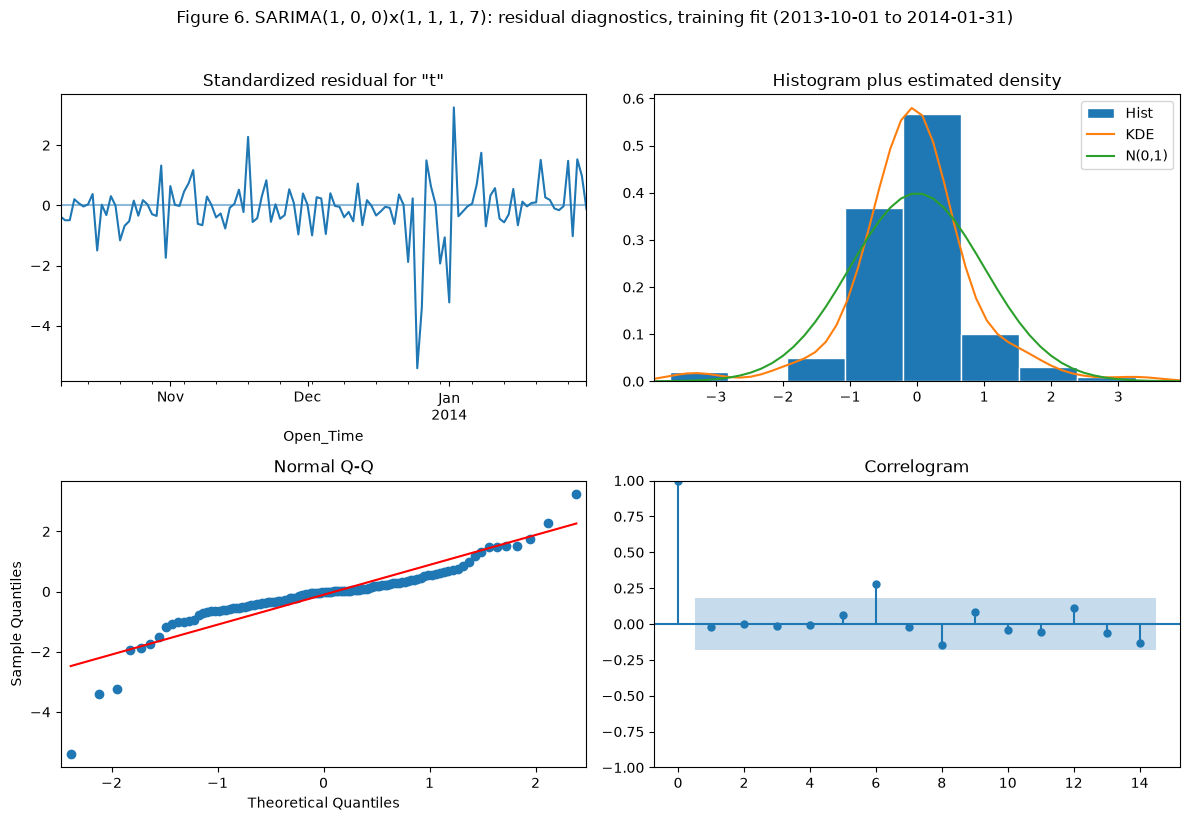

Table 10c. Residual tests, SARIMA training fit | skew -1.36, kurtosis 11.09 (normal: 0 and 3)


,Statistic,p-value,Null hypothesis
Jarque-Bera (normality),352.231,0.0,residuals are normally distributed
Heteroskedasticity (first third against last third),5.707,0.0,residual variance is the same at the start and...


In [18]:
fig = sarima_res.plot_diagnostics(figsize=(12, 8), lags=14)
fig.suptitle(f"Figure 6. SARIMA{sarima_order}x{sarima_sorder}: residual diagnostics, training fit "
             f"({train.index[0].date()} to {train.index[-1].date()})", y=1.02)
fig.tight_layout()
plt.show()

jb = np.asarray(sarima_res.test_normality("jarquebera")).ravel()          # statistic, p-value, skew, kurtosis
het = np.asarray(sarima_res.test_heteroskedasticity("breakvar")).ravel()  # statistic, p-value
diag = pd.DataFrame({"Statistic": [jb[0], het[0]], "p-value": [jb[1], het[1]],
                     "Null hypothesis": ["residuals are normally distributed",
                                         "residual variance is the same at the start and the end"]},
                    index=["Jarque-Bera (normality)", "Heteroskedasticity (first third against last third)"])
print(f"Table 10c. Residual tests, SARIMA training fit | skew {jb[2]:.2f}, kurtosis {jb[3]:.2f} (normal: 0 and 3)")
display(diag.round(3))

<details>
<summary><b>Code notes, line by line</b></summary>

- `sarima_res.plot_diagnostics(figsize=(12, 8), lags=14)` : statsmodels' four standard residual checks for the training fit (start-up residuals are skipped automatically).
- `fig.suptitle(...); fig.tight_layout(); plt.show()` : Title and display.
- `np.asarray(sarima_res.test_normality("jarquebera")).ravel()` : Jarque-Bera test: statistic, p-value, skew and kurtosis of the residuals.
- `np.asarray(sarima_res.test_heteroskedasticity("breakvar")).ravel()` : Compares residual variance in the first and last thirds of the sample: statistic and p-value.
- `diag = pd.DataFrame({...})` : Table 10c: both tests with their null hypotheses. p < 0.05 rejects the null.

</details>

**Result.** The residuals are not normally distributed: Jarque-Bera 352.2, p < 0.001, with skew -1.36 and kurtosis 11.1 against 0 and 3 for a normal distribution (Table 10c). Figure 6 shows where this comes from: one deep negative spike at New Year (about -5.5 standard deviations, a day the model over-forecast badly) and a few smaller ones in late December, which are the points far below the line at the lower end of the Q-Q plot. Apart from those days the residuals stay within about ±2, and the histogram is narrower and taller than N(0,1). The variance also changes: the last third of the training period (late December to January) has 5.7 times the residual variance of the first third (p < 0.001, Table 10c). The correlogram has one bar just outside the band, at lag 6 (about 0.27); all the others are inside, and the Ljung-Box test over all lags finds no significant leftover pattern (Table 10b: p = 0.18 and 0.17).

**What it means.** The weekly pattern is captured, so the point forecast is usable. The holiday days make the residuals heavy-tailed and uneven, so the simulated 10% to 90% ranges are too narrow: in section 17 the 80% ranges contained the actual 4-week total only half of the time (Table 17a).

## 11. Actual against predicted, each model

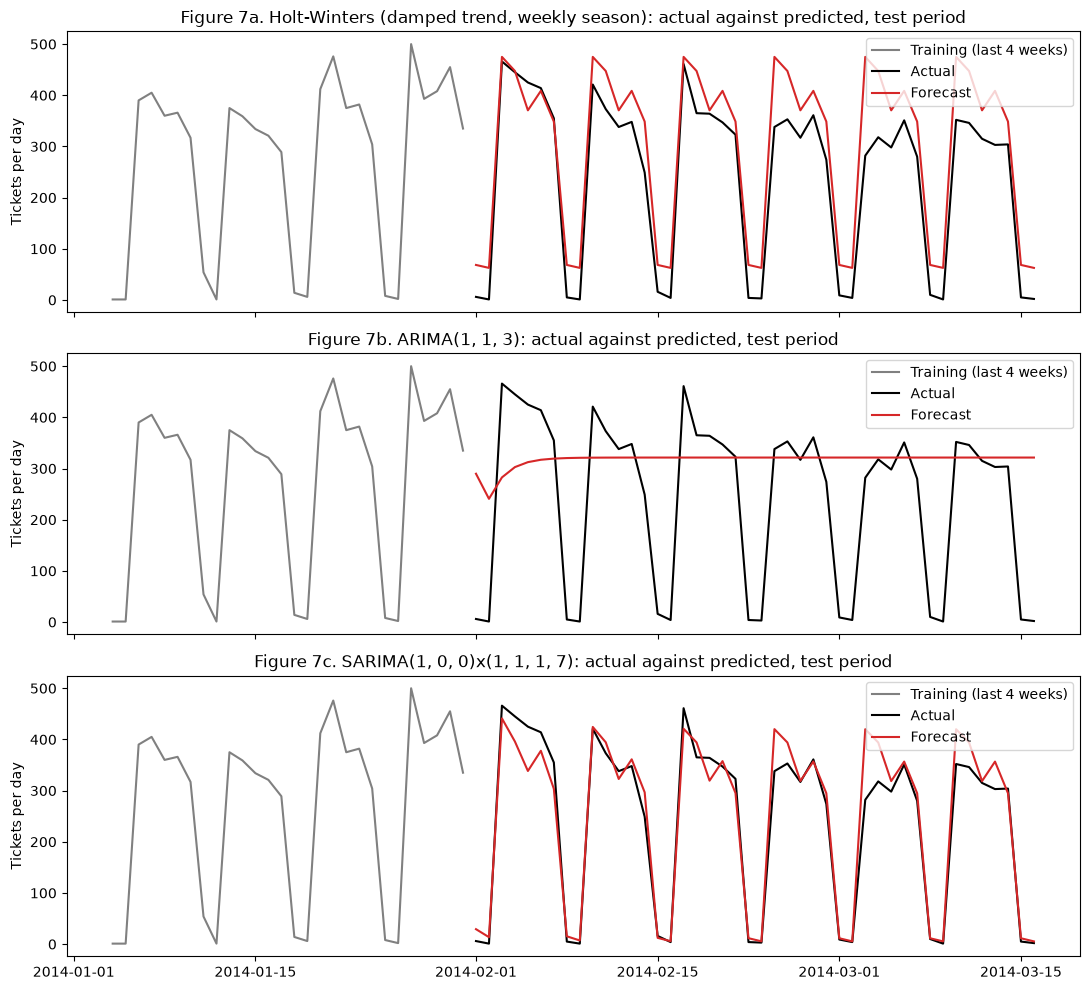

In [19]:
fcs = {"Seasonal naive (baseline)": fc_naive, "Holt-Winters": fc_hw, "ARIMA": fc_arima, "SARIMA": fc_sarima}
labels = {"Holt-Winters": "Holt-Winters (damped trend, weekly season)",
          "ARIMA": f"ARIMA{arima_order}",
          "SARIMA": f"SARIMA{sarima_order}x{sarima_sorder}"}

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, name, tag in zip(axes, ["Holt-Winters", "ARIMA", "SARIMA"], "abc"):
    ax.plot(train.index[-28:], train.iloc[-28:], color="grey", label="Training (last 4 weeks)")
    ax.plot(test.index, test, color="black", label="Actual")
    ax.plot(test.index, fcs[name], color="tab:red", label="Forecast")
    ax.set_title(f"Figure 7{tag}. {labels[name]}: actual against predicted, test period")
    ax.set_ylabel("Tickets per day")
    ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `fcs = {...}` : The four test-period forecasts in one dictionary.
- `labels = {...}` : Display names including the chosen orders.
- `for ax, name in zip(axes, [...]):` : One panel per model.
- `ax.plot(train.index[-28:], ...)` : Last four training weeks in grey, for context.
- `ax.plot(test.index, test); ax.plot(test.index, fcs[name])` : Actual (black) against forecast (red).

</details>

**Result.** Figure 7c: SARIMA follows the weekday peaks and the weekend drops to near zero through the whole test period. Figure 7b: ARIMA has no weekly term; after a few days its forecast flattens at about 320 tickets a day, so it misses every weekend by about 300 tickets. Figure 7a: Holt-Winters keeps the weekly shape but runs too high: about 65 tickets on weekend days against fewer than 10 actual, and above the actual on most weekdays from mid-February. Table 12 measures these errors.

## 12. Model comparison on the test period
- **MAE**: average absolute error in tickets per day.
- **RMSE**: like MAE, but large errors count more.
- **MAPE**: average error as a percentage. On single days it is distorted by quiet weekends (a 5-ticket error on a 10-ticket Sunday is 50%), so it is shown for **weekdays** and for **weekly totals** (full weeks only). WAPE (total absolute error as a share of total tickets) is added as a stable percentage.
- The better model is the one with the lowest **WAPE**: it needs both the daily pattern and the totals to be right. Weekly-total MAPE alone is not used to choose, because a flat forecast that ignores the weekly cycle can still get weekly totals roughly right. The model is picked on the test period, so its score there is optimistic.

In [20]:
def full_weeks(s):
    g = s.resample("W-SUN")
    tot, n = g.sum(), g.size()
    return tot[n == 7]

def metrics(actual, fc):
    err = fc - actual
    wd = actual.index.day_of_week < 5
    aw, fw = full_weeks(actual), full_weeks(fc)
    return {"MAE (tickets/day)": err.abs().mean(),
            "RMSE (tickets/day)": np.sqrt((err ** 2).mean()),
            "MAPE % (weekdays)": (err[wd].abs() / actual[wd]).mean() * 100,
            "MAPE % (weekly totals)": ((fw - aw).abs() / aw).mean() * 100,
            "WAPE %": err.abs().sum() / actual.sum() * 100}

comparison = pd.DataFrame({k: metrics(test, v) for k, v in fcs.items()}).T.round(2)
print("Table 12. Model comparison, test period 1 Feb to 16 Mar 2014 (one forecast made on 31 Jan)")
display(comparison)

best = comparison.drop(index="Seasonal naive (baseline)")["WAPE %"].idxmin()
gap = comparison.loc["Seasonal naive (baseline)", "WAPE %"] - comparison.loc[best, "WAPE %"]
print(f"Better model: {labels[best]} | WAPE {comparison.loc[best, 'WAPE %']}% "
      f"({'better' if gap > 0 else 'not better'} than the seasonal naive baseline by {abs(gap):.2f} points)")

Table 12. Model comparison, test period 1 Feb to 16 Mar 2014 (one forecast made on 31 Jan)


,MAE (tickets/day),RMSE (tickets/day),MAPE % (weekdays),MAPE % (weekly totals),WAPE %
Seasonal naive (baseline),51.57,73.45,22.69,20.93,21.49
Holt-Winters,63.53,73.31,20.07,25.40,26.48
ARIMA,131.37,182.69,13.05,28.76,54.75
SARIMA,26.74,39.39,10.72,9.12,11.14


Better model: SARIMA(1, 0, 0)x(1, 1, 1, 7) | WAPE 11.14% (better than the seasonal naive baseline by 10.35 points)


<details>
<summary><b>Code notes, line by line</b></summary>

- `def full_weeks(s):` : Weekly totals (Monday to Sunday), keeping only complete 7-day weeks.
- `def metrics(actual, fc):` : All measures for one forecast.
- `err = fc - actual` : Daily error (positive = over-forecast).
- `"MAE": err.abs().mean()` : Mean absolute error, tickets per day.
- `"RMSE": np.sqrt((err ** 2).mean())` : Root mean squared error: large misses weigh more.
- `"MAPE % (weekdays)": (err[wd].abs() / actual[wd]).mean() * 100` : Average % error on weekdays only (weekend days are tiny and would distort it).
- `"MAPE % (weekly totals)"` : Average % error of the weekly totals.
- `"WAPE %": err.abs().sum() / actual.sum() * 100` : Total absolute error as a share of total tickets: a stable % that weights busy days more.
- `comparison = pd.DataFrame({k: metrics(test, v) ...}).T` : One row per model.
- `best = comparison.drop(index=baseline)["WAPE %"].idxmin()` : Best model by WAPE, excluding the baseline.
- `gap = baseline WAPE - best WAPE` : How much better than the baseline it is.

</details>

**Result (single forecast made on 31 January; Table 12 and Figure 7).**
- SARIMA(1, 0, 0)x(1, 1, 1, 7) is the best model on every measure: WAPE 11.1%, MAE 26.7 tickets a day, weekly-total MAPE 9.1%, against the seasonal naive baseline's 21.5%, 51.6 and 20.9%.
- Holt-Winters is worse than the baseline (WAPE 26.5%): its seasonal smoothing came out at zero (Table 8), so it over-forecasts every weekend (Figure 7a).
- ARIMA(1, 1, 3) has no weekly seasonality. Its forecast stays close to the weekday level (Figure 7b), so it does reasonably on weekdays (MAPE 13.1%) but over-forecasts every weekend, giving the worst WAPE (54.8%) and weekly-total error (28.8%).

One forecast period can mislead, so section 17 tests the models on 12 rolling 4-week origins (and Appendix A on 38 rolling 7-day origins).

### 12b. Standard MAE, RMSE and MAPE for every model (scikit-learn)
The same three measures as the course template (`mean_absolute_error`, `mean_squared_error`, `mean_absolute_percentage_error`), applied to every forecast in one loop: the seasonal naive baseline, Holt-Winters, ARIMA and SARIMA. MAE and RMSE equal the section 12 columns (a cross-check). MAPE is shown over all days (as in the template), over weekdays, and on weekly totals (Table 12b-2), the scale used for planning.

Seasonal naive (baseline) MAE: 51.57 | RMSE: 73.45 | MAPE (all days): 32.92 % | MAPE (weekdays): 22.69 %
Holt-Winters MAE: 63.53 | RMSE: 73.31 | MAPE (all days): 768.67 % | MAPE (weekdays): 20.07 %
ARIMA MAE: 131.37 | RMSE: 182.69 | MAPE (all days): 3742.75 % | MAPE (weekdays): 13.05 %
SARIMA MAE: 26.74 | RMSE: 39.39 | MAPE (all days): 89.67 % | MAPE (weekdays): 10.72 %

Table 12b-1. Daily forecasts, test period (44 days)


,MAE (tickets/day),RMSE (tickets/day),MAPE % (all days),MAPE % (weekdays)
Seasonal naive (baseline),51.57,73.45,32.92,22.69
Holt-Winters,63.53,73.31,768.67,20.07
ARIMA,131.37,182.69,3742.75,13.05
SARIMA,26.74,39.39,89.67,10.72


Table 12b-2. Weekly totals, test period (6 complete weeks)


,MAE (tickets/week),RMSE (tickets/week),MAPE % (weekly totals)
Seasonal naive (baseline),346.00,390.76,20.93
Holt-Winters,423.13,462.94,25.40
ARIMA,479.46,524.08,28.76
SARIMA,157.26,174.16,9.12


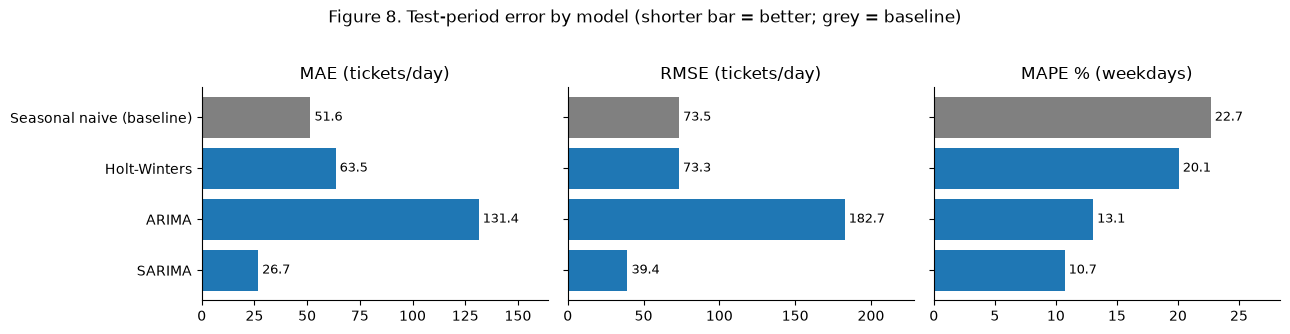

In [21]:
actual_values = test
is_weekday = test.index.day_of_week < 5

std_rows, week_rows = {}, {}
for name, predictions in fcs.items():
    mae = mean_absolute_error(actual_values, predictions)
    rmse = np.sqrt(mean_squared_error(actual_values, predictions))
    mape = mean_absolute_percentage_error(actual_values, predictions) * 100
    mape_wd = mean_absolute_percentage_error(actual_values[is_weekday], predictions[is_weekday]) * 100
    print(f"{name} MAE: {mae:.2f} | RMSE: {rmse:.2f} | MAPE (all days): {mape:.2f} % | MAPE (weekdays): {mape_wd:.2f} %")
    std_rows[name] = {"MAE (tickets/day)": mae, "RMSE (tickets/day)": rmse,
                      "MAPE % (all days)": mape, "MAPE % (weekdays)": mape_wd}

    aw, fw = full_weeks(actual_values), full_weeks(predictions)
    week_rows[name] = {"MAE (tickets/week)": mean_absolute_error(aw, fw),
                       "RMSE (tickets/week)": np.sqrt(mean_squared_error(aw, fw)),
                       "MAPE % (weekly totals)": mean_absolute_percentage_error(aw, fw) * 100}

std_eval = pd.DataFrame(std_rows).T.round(2)
week_eval = pd.DataFrame(week_rows).T.round(2)
print(f"\nTable 12b-1. Daily forecasts, test period ({len(test)} days)")
display(std_eval)
print(f"Table 12b-2. Weekly totals, test period ({len(full_weeks(actual_values))} complete weeks)")
display(week_eval)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, col in zip(axes, ["MAE (tickets/day)", "RMSE (tickets/day)", "MAPE % (weekdays)"]):
    vals = std_eval[col]
    ax.barh(vals.index, vals.values, color=["grey" if "naive" in n else "tab:blue" for n in vals.index])
    for k, v in enumerate(vals.values):
        ax.text(v, k, f" {v:.1f}", va="center", fontsize=9)
    ax.set_title(col)
    ax.set_xlim(0, vals.max() * 1.25)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].invert_yaxis()
fig.suptitle("Figure 8. Test-period error by model (shorter bar = better; grey = baseline)", y=1.03)
fig.tight_layout()
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `actual_values = test` : The 44 actual daily counts, named as in the course template.
- `is_weekday = test.index.day_of_week < 5` : Mask for Monday to Friday.
- `for name, predictions in fcs.items():` : Loops over the seasonal naive baseline, Holt-Winters, ARIMA and SARIMA.
- `mean_absolute_error(actual_values, predictions)` : MAE: average miss in tickets per day.
- `np.sqrt(mean_squared_error(actual_values, predictions))` : RMSE: square root of the average squared miss.
- `mean_absolute_percentage_error(actual_values, predictions) * 100` : MAPE over all 44 days, as in the template. scikit-learn returns a fraction, so x 100 gives %.
- `mean_absolute_percentage_error(actual_values[is_weekday], predictions[is_weekday]) * 100` : MAPE over weekdays only.
- `print(f"{name} MAE: ...")` : The same printout style as the template, one line per model.
- `std_eval = pd.DataFrame(std_rows).T.round(2)` : Table 12b-1: all models side by side.
- `aw, fw = full_weeks(actual_values), full_weeks(predictions)` : Weekly totals for complete weeks.
- `week_rows[name] = {MAE, RMSE, MAPE} on weekly totals` : Table 12b-2: the same three measures on weekly totals, the scale used for planning.
- `fig, axes = plt.subplots(1, 3, ...); barh(...)` : Bar chart of MAE, RMSE and weekday MAPE per model (shorter bar = better).

</details>

**Result.** MAE and RMSE match Table 12 exactly (Table 12b-1). On weekdays, MAPE ranks the models as MAE does: SARIMA 10.7%, ARIMA 13.1%, Holt-Winters 20.1%, baseline 22.7% (Table 12b-1, Figure 8). On weekly totals, the planning scale, SARIMA misses by 157 tickets a week on average (MAPE 9.1%), against 346 (20.9%) for the baseline and 423 and 479 for Holt-Winters and ARIMA (Table 12b-2). Over all days, MAPE gives a very different order: baseline 32.9%, SARIMA 89.7%, Holt-Winters 768.7% and ARIMA 3,742.8%.

**Why all-days MAPE misleads here.** MAPE divides each day's error by that day's count. Weekend days in the test period have only 1 to 16 tickets, so a model that misses a Sunday by 40 tickets scores several hundred percent on that day, and the 14 weekend days dominate the average. The baseline scores best on this measure only because it copies last week's tiny weekend counts. That is why section 12 chooses the model on WAPE and reports MAPE on weekdays and weekly totals; the all-days column is kept only for comparability with the template.

## 13. All models together

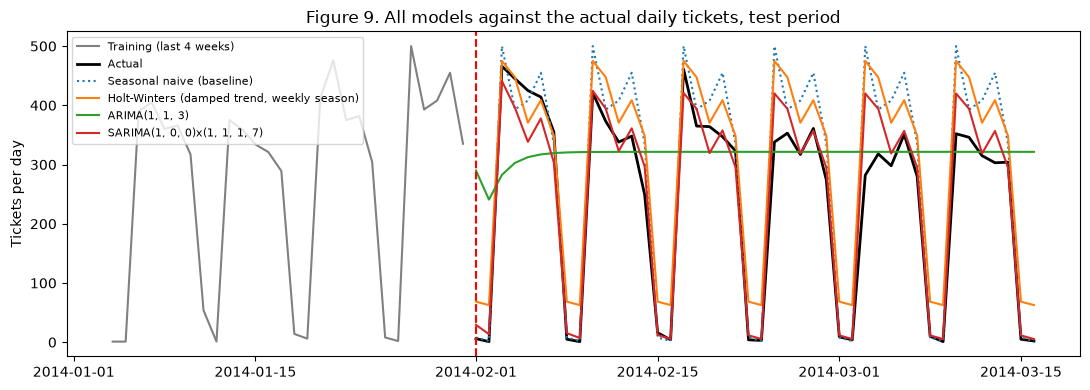

In [22]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train.index[-28:], train.iloc[-28:], color="grey", label="Training (last 4 weeks)")
ax.plot(test.index, test, color="black", linewidth=2, label="Actual")
for name, style in [("Seasonal naive (baseline)", ":"), ("Holt-Winters", "-"), ("ARIMA", "-"), ("SARIMA", "-")]:
    ax.plot(test.index, fcs[name], linestyle=style, label=labels.get(name, name))
ax.axvline(pd.Timestamp(TEST_START), color="red", linestyle="--")
ax.set_title("Figure 9. All models against the actual daily tickets, test period")
ax.set_ylabel("Tickets per day")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `ax.plot(...) for each model` : All four forecasts and the actual on one chart; the baseline is dotted.
- `ax.axvline(TEST_START, ...)` : Start of the test period.

</details>

**Result.** Figure 9 overlays the four forecasts. SARIMA (red) stays closest to the actual line on weekdays and at weekends; the seasonal naive baseline (dotted) repeats a busy late-January week and sits above the actual on most weekdays; Holt-Winters (orange) is too high at weekends; ARIMA's flat line is furthest from the actual. This matches the WAPE ranking in Table 12 (11.1% for SARIMA against 54.8% for ARIMA).

## 14. Monthly volume and the working-day run-rate
Closed counts are complete for all six months (the extract is cut by close date); opened counts are censored at the end of March. The run-rate predicts a month as its number of weekdays times the average opened tickets per weekday in the earlier months.

In [23]:
def monthly_count(col):
    return df.groupby(df[col].dt.to_period("M")).size().loc["2013-10":"2014-03"]

mtab = pd.DataFrame({"opened": monthly_count("Open_Time"), "closed": monthly_count("Close_Time")})
mtab["weekdays"] = [len(pd.bdate_range(p.start_time.normalize(), p.end_time.normalize())) for p in mtab.index]
mtab["opened/weekday"] = (mtab["opened"] / mtab["weekdays"]).round(0)
mtab["closed/weekday"] = (mtab["closed"] / mtab["weekdays"]).round(0)
print("Table 14a. Tickets per month and per weekday")
display(mtab)

sh = (w.assign(month=w["Open_Time"].dt.to_period("M"))
        .groupby(["month", "CI_Cat"]).size().unstack(fill_value=0))
top = w["CI_Cat"].value_counts().head(5).index
print("Table 14b. Share of opened tickets by asset type, per month")
display(sh.div(sh.sum(axis=1), axis=0)[top].round(3))

mm = mtab.loc["2013-10":"2014-02"]
rows = []
for i in range(2, len(mm)):
    rate_i = mm["opened"].iloc[:i].sum() / mm["weekdays"].iloc[:i].sum()
    pred_i = rate_i * mm["weekdays"].iloc[i]
    rows.append({"Month": str(mm.index[i]), "Predicted": round(pred_i), "Actual": int(mm["opened"].iloc[i]),
                 "Error %": round((pred_i / mm["opened"].iloc[i] - 1) * 100, 1)})
print("Table 14c. Run-rate backtest: each month predicted from the months before it (March excluded: censored)")
display(pd.DataFrame(rows).set_index("Month"))

Table 14a. Tickets per month and per weekday


,opened,closed,weekdays,opened/weekday,closed/weekday
2013-10,8606,8544,23,374.0,371.0
2013-11,8128,8052,21,387.0,383.0
2013-12,6743,7013,22,306.0,319.0
2014-01,8270,8210,23,360.0,357.0
2014-02,7377,7542,20,369.0,377.0
2014-03,6332,7245,21,302.0,345.0


Table 14b. Share of opened tickets by asset type, per month


CI_Cat,application,subapplication,computer,storage,hardware
month,,,,,
2013-10,0.707,0.167,0.086,0.010,0.008
2013-11,0.715,0.155,0.084,0.016,0.005
2013-12,0.710,0.162,0.085,0.017,0.004
2014-01,0.695,0.173,0.071,0.016,0.018
2014-02,0.708,0.174,0.069,0.016,0.008
2014-03,0.675,0.175,0.088,0.018,0.017


Table 14c. Run-rate backtest: each month predicted from the months before it (March excluded: censored)


,Predicted,Actual,Error %
Month,,,
2013-12,8367,6743,24.1
2014-01,8181,8270,-1.1
2014-02,7134,7377,-3.3


<details>
<summary><b>Code notes, line by line</b></summary>

- `def monthly_count(col):` : Tickets per month by any date column, October 2013 to March 2014.
- `mtab = pd.DataFrame({"opened": ..., "closed": ...})` : Opened and closed per month (closed is complete for every month).
- `len(pd.bdate_range(start, end))` : Number of weekdays (Monday to Friday) in each month.
- `opened/weekday, closed/weekday` : Tickets per working day: removes the effect of month length.
- `sh = w.assign(month=...).groupby(["month", "CI_Cat"]).size().unstack()` : Tickets per month and asset type.
- `sh.div(sh.sum(axis=1), axis=0)[top]` : Table 14b: each asset type's share per month.
- `for i in range(2, len(mm)):` : Run-rate backtest from December: each month predicted from the months before it.
- `rate_i = opened so far / weekdays so far; pred_i = rate_i * weekdays in month i` : The run-rate prediction.
- `"Error %": (pred_i / actual - 1) * 100` : Positive = over-forecast.

</details>

**Result.** Ordinary months run at about 360 to 387 tickets per weekday; December 2013 ran at 306, about 18% below the other months (Christmas) (Table 14a). The run-rate missed December by 24.1% (no Christmas in its history yet) and January and February by 1.1% and 3.3% (Table 14c). Asset-type shares are stable from month to month (applications 68% to 72%, Table 14b), so they can be used to split a total forecast.

## 15. Final SARIMA model and the quarterly and annual forecast
**Objective 2:** forecast incident volume quarterly and annually, so ABC Tech can prepare resources and technology. 15a trains the final model on all observations; 15b produces the forecast.

### 15a. Train the final SARIMA model using all observations
The structure chosen on the training data, SARIMA(1, 0, 0)x(1, 1, 1, 7), is fitted again on **all 167 days** of the modelling window (1 October 2013 to 16 March 2014, training and test together). This gives the model the most recent data (February and early March) before forecasting the future. The orders are not searched again; only the parameters are re-estimated. Days outside the window (the backlog before October and the censored days from 17 March) are left out on purpose (section 3).

The residual diagnostics are repeated for this final fit, because it is the model that produces the quarterly and annual forecast.

Final model: SARIMA(1, 0, 0)x(1, 1, 1, 7)
Fitted on 167 daily observations, 2013-10-01 to 2014-03-16 (training 123 days + test 44 days: the whole modelling window)
Converged: True | AIC: 1749.1
Table 15a-1. SARIMA parameters, training fit against final fit


,Training fit (123 days),Final fit (167 days)
ar.L1,0.484,0.469
ar.S.L7,0.210,0.232
ma.S.L7,-1.000,-0.997
sigma2,3371.544,2772.243


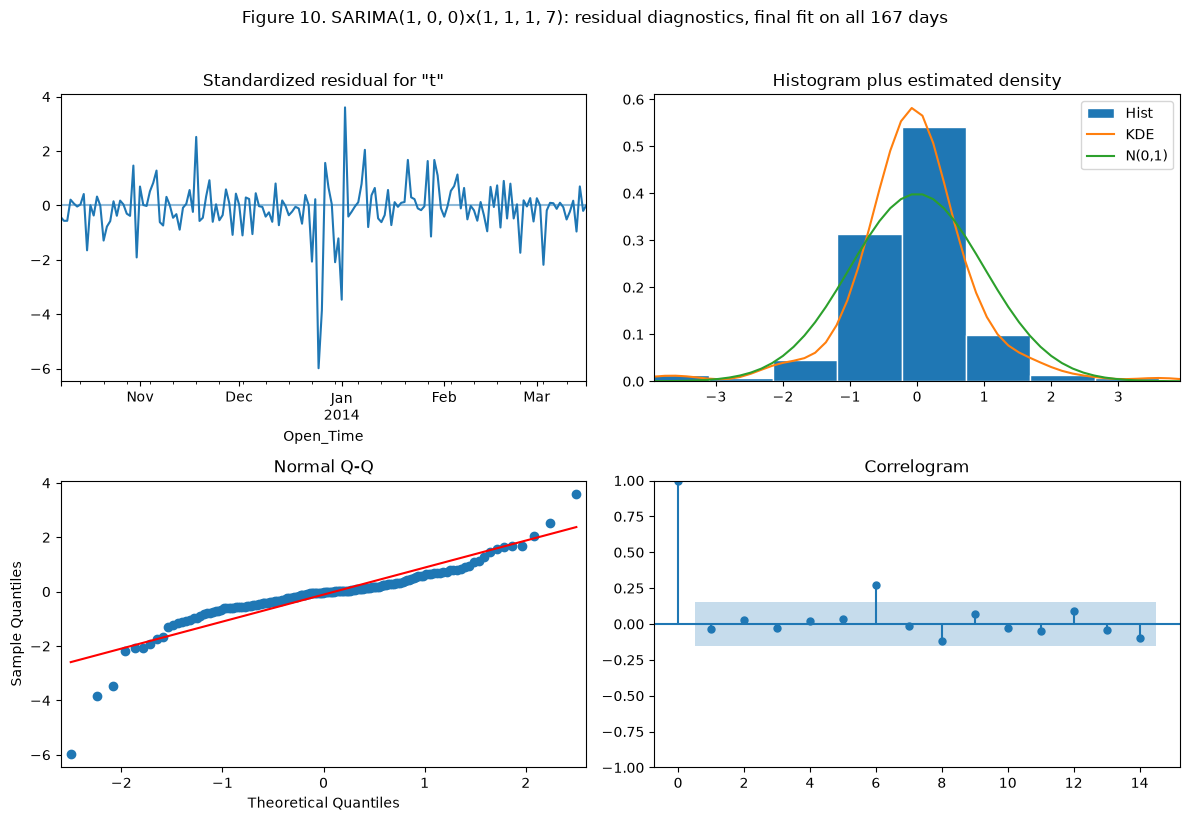

Table 15a-2. Ljung-Box test on the final fit's residuals (p > 0.05 means no leftover pattern):


,lb_stat,lb_pvalue
7,13.008807,0.071894
14,20.435357,0.117002


In [24]:
assert best == "SARIMA", "the steps below assume SARIMA was chosen in section 12"
final_sarima_model = SARIMAX(daily, order=sarima_order, seasonal_order=sarima_sorder)
final_res = final_sarima_model.fit(disp=False)

n_fit = int(final_res.nobs)
print(f"Final model: {labels[best]}")
print(f"Fitted on {n_fit} daily observations, {daily.index[0].date()} to {daily.index[-1].date()} "
      f"(training {len(train)} days + test {len(test)} days: the whole modelling window)")
print("Converged:", final_res.mle_retvals.get("converged"), "| AIC:", round(final_res.aic, 1))

params = pd.DataFrame({f"Training fit ({len(train)} days)": sarima_res.params,
                       f"Final fit ({n_fit} days)": final_res.params}).round(3)
print("Table 15a-1. SARIMA parameters, training fit against final fit")
display(params)

fig = final_res.plot_diagnostics(figsize=(12, 8), lags=14)
fig.suptitle(f"Figure 10. {labels[best]}: residual diagnostics, final fit on all {n_fit} days", y=1.02)
fig.tight_layout()
plt.show()
print("Table 15a-2. Ljung-Box test on the final fit's residuals (p > 0.05 means no leftover pattern):")
display(acorr_ljungbox(final_res.resid.iloc[8:], lags=[7, 14]))

<details>
<summary><b>Code notes, line by line</b></summary>

- `assert best == "SARIMA"` : Stops with a clear message if a different model had been chosen in section 12.
- `SARIMAX(daily, order=sarima_order, seasonal_order=sarima_sorder)` : The final SARIMA model on all observations (`daily` = all 167 days), with the orders chosen on the training data.
- `final_res = final_sarima_model.fit(disp=False)` : Re-estimates the parameters; disp=False hides optimiser messages. `final_res` is used by the forecast in 15b.
- `n_fit = int(final_res.nobs)` : Number of observations the model was fitted on (167).
- `print(...)` : States the fitting period, convergence and AIC.
- `pd.DataFrame({training fit: sarima_res.params, final fit: final_res.params})` : Table 15a-1: the parameters from 123 days against all 167 days.
- `final_res.plot_diagnostics(figsize=(12, 8), lags=14)` : The four residual checks (residuals over time, histogram, Q-Q plot, correlogram) for the final fit.
- `acorr_ljungbox(final_res.resid.iloc[8:], lags=[7, 14])` : Ljung-Box test on the final fit's residuals, skipping the first 8 start-up values.

</details>

**Result.** The final model converged on all 167 days (AIC 1749.1; not comparable with the training fit's 1296.8, because the data differ). Its parameters barely move (Table 15a-1): the daily AR term from 0.484 to 0.469, the weekly AR term from 0.210 to 0.232, and the weekly MA term stays at about -1 (-1.000 and -0.997). A weekly MA term of -1 means the weekly pattern is effectively fixed, one stable profile per weekday, which is why the long-range forecast repeats the same week. The residual variance falls (sigma2 from 3,372 to 2,772) because the added February and early-March days are calmer than the holiday weeks. Figure 10 repeats the four checks for this fit and shows the same picture as the training fit: the New Year spike (about -6) and heavy lower tail, and the same lag-6 bar just outside the band. Over all lags no significant pattern is left (Table 15a-2: Ljung-Box p = 0.07 at lag 7 and 0.12 at lag 14, both above 0.05, lag 7 close). Its accuracy was measured beforehand on held-out data (sections 12 and 17), because after refitting no hold-out days are left.

### 15b. Forecast the quarterly and annual ticket volume (all tickets; incidents only in section 18)
The final model forecasts every day from 17 March 2014 to 31 March 2015. The daily forecasts are summed to calendar quarters (Q2 2014 to Q1 2015), to months, and to the next 12 months (April 2014 to March 2015). The 10% to 90% range comes from 500 simulated future paths. A run-rate check (average tickets per weekday, October to February, times the weekdays in each quarter) is shown alongside. The split by asset type uses each type's share of tickets from December to February.

In [25]:
h_future = (pd.Timestamp("2015-03-31") - daily.index[-1]).days
future_idx = pd.date_range(daily.index[-1] + pd.Timedelta(days=1), periods=h_future, freq="D")

point = pd.Series(np.clip(np.asarray(final_res.forecast(h_future)), 0, None), index=future_idx)
np.random.seed(42)
sims = np.asarray(final_res.simulate(nsimulations=h_future, repetitions=500, anchor="end"))
sims = pd.DataFrame(sims.reshape(h_future, -1), index=future_idx)   # not clipped: clipping single days would bias the totals upward

q_point = point.resample("QS").sum().loc["2014-04-01":]
q_sims = sims.resample("QS").sum().loc["2014-04-01":]

base = monthly.loc["2013-10-01":"2014-02-01"]
rate = base.sum() / sum(len(pd.bdate_range(m, m + pd.offsets.MonthEnd(0))) for m in base.index)

quarters = pd.DataFrame({
    "Forecast": q_point.round(),
    "Low (10%)": q_sims.quantile(0.10, axis=1).round(),
    "High (90%)": q_sims.quantile(0.90, axis=1).round(),
    "Run-rate check": [round(rate * len(pd.bdate_range(s, s + pd.offsets.QuarterEnd(0)))) for s in q_point.index]})
quarters.index = [f"Q{(d.month - 1) // 3 + 1} {d.year}" for d in quarters.index]

annual_sims = sims.loc["2014-04-01":].sum()
annual = pd.DataFrame({"Forecast": [round(q_point.sum())],
                       "Low (10%)": [round(annual_sims.quantile(0.10))],
                       "High (90%)": [round(annual_sims.quantile(0.90))],
                       "Run-rate check": [int(quarters["Run-rate check"].sum())]},
                      index=["Next 12 months (Apr 2014 to Mar 2015)"])

print(f"Table 15b-1. Quarterly forecast of tickets opened, {labels[best]}")
display(quarters.astype(int))
print("Table 15b-2. Annual forecast")
display(annual.astype(int))

m_point = point.resample("MS").sum().loc["2014-04-01":]
m_sims = sims.resample("MS").sum().loc["2014-04-01":]
monthly_fc = pd.DataFrame({"Forecast": m_point.round(),
                           "Low (10%)": m_sims.quantile(0.10, axis=1).round(),
                           "High (90%)": m_sims.quantile(0.90, axis=1).round()}).astype(int)
monthly_fc.index = monthly_fc.index.strftime("%b %Y")
print("Table 15b-3. Monthly forecast, next 12 months")
display(monthly_fc)

recent = w[(w["Open_Time"] >= "2013-12-01") & (w["Open_Time"] < "2014-03-01")]
share = recent["CI_Cat"].value_counts(normalize=True)
share = pd.concat([share.head(5), pd.Series({"other asset types": 1 - share.head(5).sum()})])
by_field = pd.DataFrame(np.outer(share.to_numpy(), q_point.to_numpy()).round(),
                        index=share.index, columns=quarters.index)
by_field["Next 12 months"] = by_field.sum(axis=1)
by_field.index.name = "Asset type (CI_Cat)"
print("Table 15b-4. Forecast split by asset type (share of tickets, Dec 2013 to Feb 2014)")
display(by_field.astype(int))

Table 15b-1. Quarterly forecast of tickets opened, SARIMA(1, 0, 0)x(1, 1, 1, 7)


,Forecast,Low (10%),High (90%),Run-rate check
Q2 2014,23181,21026,25320,23331
Q3 2014,23569,21589,25659,23690
Q4 2014,23506,21670,25394,23690
Q1 2015,22859,21023,24886,22972


Table 15b-2. Annual forecast


,Forecast,Low (10%),High (90%),Run-rate check
Next 12 months (Apr 2014 to Mar 2015),93115,87619,99202,93683


Table 15b-3. Monthly forecast, next 12 months


,Forecast,Low (10%),High (90%)
Apr 2014,7842,6871,8855
May 2014,7792,6851,8801
Jun 2014,7547,6600,8487
Jul 2014,8198,7265,9105
Aug 2014,7442,6548,8355
Sep 2014,7930,6946,8818
Oct 2014,8106,7174,9032
Nov 2014,7147,6280,8088
Dec 2014,8253,7351,9183
Jan 2015,7792,6774,8772


Table 15b-4. Forecast split by asset type (share of tickets, Dec 2013 to Feb 2014)


,Q2 2014,Q3 2014,Q4 2014,Q1 2015,Next 12 months
Asset type (CI_Cat),,,,,
application,16315,16588,16544,16088,65535
subapplication,3933,3999,3988,3879,15799
computer,1728,1757,1752,1704,6941
storage,379,385,384,374,1522
hardware,246,251,250,243,990
other asset types,580,589,588,572,2329


<details>
<summary><b>Code notes, line by line</b></summary>

- `h_future = (31 Mar 2015 - last day).days` : Days to forecast: 17 March 2014 to 31 March 2015.
- `future_idx = pd.date_range(...)` : Dates of those days.
- `point = final_res.forecast(h_future) clipped at 0` : Point forecast for every future day from the final SARIMA model (15a).
- `np.random.seed(42); final_res.simulate(nsimulations=h_future, repetitions=500, anchor="end")` : 500 simulated future paths starting from the end of the data, each with random shocks like the past.
- `sims = pd.DataFrame(...reshape(h_future, -1))` : One column per path (not clipped, so totals are not biased upward).
- `point.resample("QS").sum().loc["2014-04-01":]` : Quarterly totals from Q2 2014 (the partial Q1 2014 is shown in 16a).
- `q_sims.quantile(0.10 / 0.90, axis=1)` : 10% and 90% points of the 500 quarterly totals: the range.
- `rate = Oct-Feb tickets / Oct-Feb weekdays; "Run-rate check"` : The run-rate (tickets per weekday) times the weekdays in each quarter.
- `annual_sims = sims.loc["2014-04-01":].sum()` : Each path's April 2014 to March 2015 total; its quantiles give the annual range.
- `m_point / m_sims / monthly_fc` : The same forecast and range per month for the next 12 months.
- `share = recent["CI_Cat"].value_counts(normalize=True)` : Asset-type shares from December to February (top 5 plus 'other').
- `np.outer(share, q_point)` : Splits each quarterly forecast by those shares.

</details>

**Result.** The quarterly forecasts are 22,859 to 23,569 tickets, each with a 10% to 90% range of about ±8%, and within 1% of the run-rate check (Table 15b-1). The next 12 months come to 93,115 (88,036 to 98,113), against 93,683 for the run-rate (Table 15b-2). By month the forecast runs from 7,133 (February 2015) to 8,253 (December 2014) (Table 15b-3). These differences come only from the number of weekdays in each month, because the model has a weekly cycle and nothing longer: December 2014 is forecast as the busiest month, although December 2013 was the quietest (Table 14a). Applications make up about 70% of the forecast in every period (Table 15b-4), using the December to February split.

## 16. Historical data and the future forecast
The history and the forecast are plotted separately for quarters (16a) and for the year (16b).

### 16a. Quarterly
Actual quarters: Q4 2013 (complete) and Q1 2014 (actual to 16 March, plus the forecast for 17 to 31 March). Forecast quarters: Q2 2014 to Q1 2015, with the 10% to 90% range from the simulated paths; grey diamonds show the run-rate check.

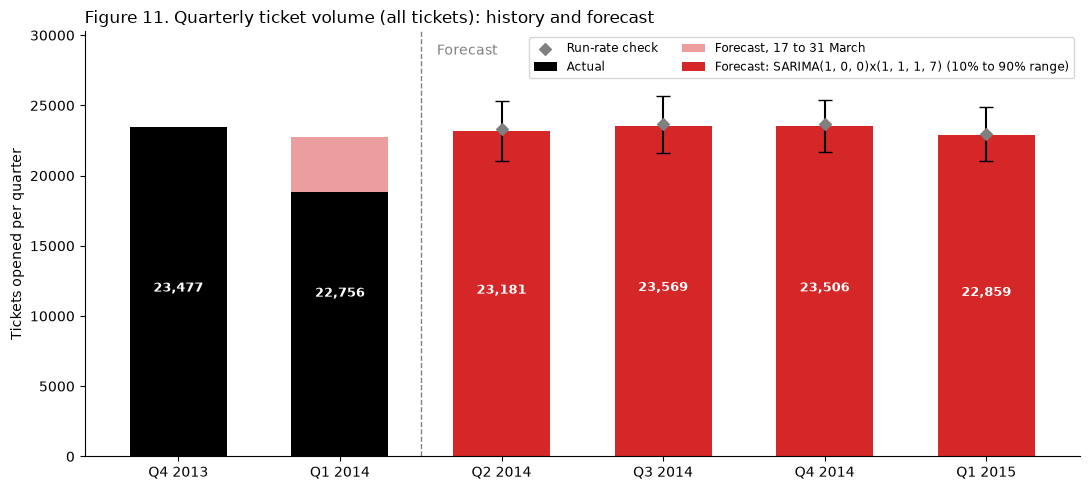

In [26]:
q4_2013 = daily.loc["2013-10-01":"2013-12-31"].sum()          # complete quarter, actual
q1_actual = daily.loc["2014-01-01":].sum()                      # 1 Jan to 16 Mar, actual
q1_rest = point.loc[:"2014-03-31"].sum()                        # 17 to 31 Mar, forecast

labels_q = ["Q4 2013", "Q1 2014"] + list(quarters.index)
x = np.arange(len(labels_q))
totals = [q4_2013, q1_actual + q1_rest] + list(quarters["Forecast"])

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x[:2], [q4_2013, q1_actual], color="black", width=0.6, label="Actual")
ax.bar(x[1], q1_rest, bottom=q1_actual, color="tab:red", alpha=0.45, width=0.6, label="Forecast, 17 to 31 March")
ax.bar(x[2:], quarters["Forecast"], color="tab:red", width=0.6,
       yerr=[quarters["Forecast"] - quarters["Low (10%)"], quarters["High (90%)"] - quarters["Forecast"]],
       capsize=5, label=f"Forecast: {labels[best]} (10% to 90% range)")
ax.scatter(x[2:], quarters["Run-rate check"], color="grey", marker="D", zorder=3, label="Run-rate check")
for k, v in enumerate(totals):
    ax.text(k, v * 0.5, f"{v:,.0f}", ha="center", color="white", fontsize=9, fontweight="bold")
ax.set_ylim(0, max(quarters["High (90%)"].max(), max(totals)) * 1.18)
ax.axvline(1.5, color="grey", linestyle="--", linewidth=1)
ax.text(1.6, ax.get_ylim()[1] * 0.97, "Forecast", va="top", color="grey")
ax.set_xticks(x)
ax.set_xticklabels(labels_q)
ax.set_ylabel("Tickets opened per quarter")
ax.set_title("Figure 11. Quarterly ticket volume (all tickets): history and forecast", loc="left")
ax.legend(loc="upper right", fontsize=8.5, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/track2_quarterly_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `q4_2013 = daily.loc["2013-10-01":"2013-12-31"].sum()` : The one complete actual quarter.
- `q1_actual / q1_rest` : Q1 2014: actual to 16 March, plus the forecast for 17 to 31 March.
- `labels_q / x / totals` : Bar labels, positions and the total of each bar.
- `ax.bar(x[:2], ..., color="black")` : Actual bars.
- `ax.bar(x[1], q1_rest, bottom=q1_actual, ...)` : Stacks the forecast part of Q1 2014 on top of its actual part.
- `ax.bar(x[2:], quarters["Forecast"], yerr=[...], capsize=5)` : Forecast quarters with error bars from the 10% to the 90% simulated total.
- `ax.scatter(x[2:], quarters["Run-rate check"], marker="D")` : Run-rate check as grey diamonds.
- `ax.text(k, v * 0.5, ...)` : Writes each total inside its bar.
- `ax.axvline(1.5, ...); ax.text(1.6, ..., "Forecast")` : Separates history from forecast.
- `fig.savefig("../reports/figures/track2_quarterly_forecast.png", ...)` : Saves the figure.

</details>

**Result.** In Figure 11 the four forecast quarters (22,859 to 23,569; Table 15b-1) sit level with the actual Q4 2013 (23,477), and the run-rate check (grey diamonds) is within 1% of the forecast in every quarter. The bars differ only by the number of weekdays: Q1 2015 is lowest because it has 64 weekdays against 65 or 66. The model has no Christmas dip, so Q4 2014 is likely overstated by about 6% (section 14, Table 14a).

### 16b. Annual
Left: tickets per month, actual from October 2013 and forecast for the next 12 months (April 2014 to March 2015) with the 10% to 90% range. Right: the 12-month total from the model, the run-rate check, and the total if the lower early-March level continues.

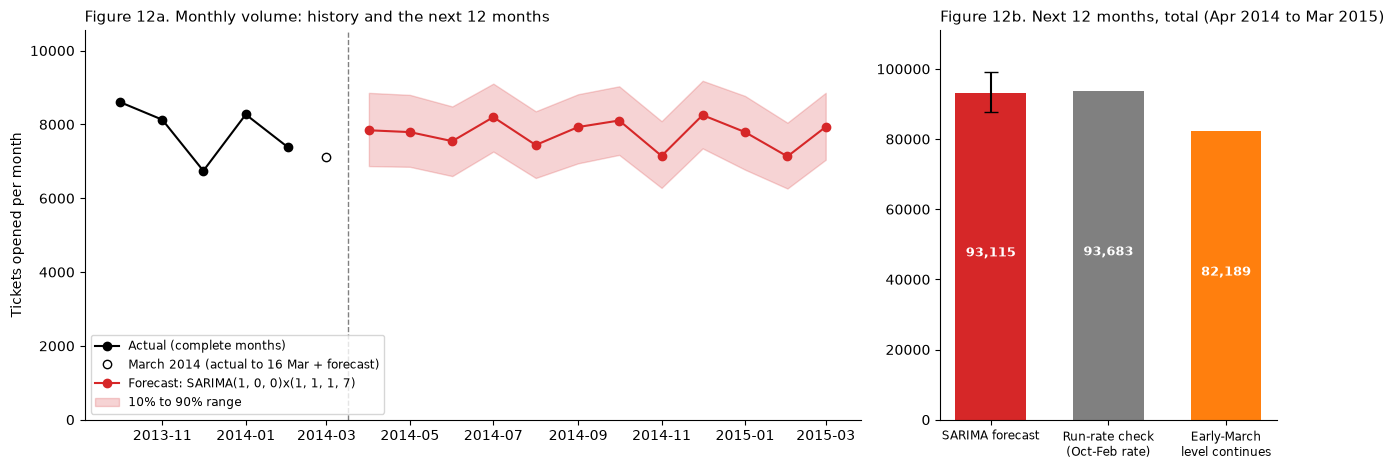

In [27]:
m_hist = daily.resample("MS").sum()
m_full = m_hist.loc[:"2014-02-01"]                                         # complete months, actual
mar_2014 = m_hist.loc["2014-03-01"] + point.loc[:"2014-03-31"].sum()      # actual to 16 Mar + forecast
m_fc = point.resample("MS").sum().loc["2014-04-01":]
m_band = sims.resample("MS").sum().loc["2014-04-01":]

march = daily.loc["2014-03-01":]
march_rate = march[march.index.day_of_week < 5].mean()                    # tickets per weekday, 1 to 16 Mar
year_weekdays = len(pd.bdate_range("2014-04-01", "2015-03-31"))
fc_year, lo_year, hi_year = annual.iloc[0][["Forecast", "Low (10%)", "High (90%)"]]
totals_y = pd.Series({"SARIMA forecast": fc_year,
                      "Run-rate check\n(Oct-Feb rate)": annual["Run-rate check"].iloc[0],
                      "Early-March\nlevel continues": march_rate * year_weekdays})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [3, 1.3]})
ax1.plot(m_full.index, m_full.values, color="black", marker="o", label="Actual (complete months)")
ax1.plot([pd.Timestamp("2014-03-01")], [mar_2014], color="black", marker="o", markerfacecolor="white",
         linestyle="none", label="March 2014 (actual to 16 Mar + forecast)")
ax1.plot(m_fc.index, m_fc.values, color="tab:red", marker="o", label=f"Forecast: {labels[best]}")
ax1.fill_between(m_fc.index, m_band.quantile(0.10, axis=1), m_band.quantile(0.90, axis=1),
                 color="tab:red", alpha=0.2, label="10% to 90% range")
ax1.axvline(pd.Timestamp("2014-03-17"), color="grey", linestyle="--", linewidth=1)
ax1.set_ylim(0, max(m_hist.max(), m_band.quantile(0.90, axis=1).max()) * 1.15)
ax1.set_ylabel("Tickets opened per month")
ax1.set_title("Figure 12a. Monthly volume: history and the next 12 months", loc="left", fontsize=11)
ax1.legend(loc="lower left", fontsize=8.5)

ax2.bar(range(3), totals_y.values, color=["tab:red", "grey", "tab:orange"], width=0.6)
ax2.errorbar(0, fc_year, yerr=[[fc_year - lo_year], [hi_year - fc_year]], color="black", capsize=5)
for k, v in enumerate(totals_y.values):
    ax2.text(k, v * 0.5, f"{v:,.0f}", ha="center", color="white", fontsize=9, fontweight="bold")
ax2.set_xticks(range(3))
ax2.set_xticklabels(totals_y.index, fontsize=8.5)
ax2.set_ylim(0, hi_year * 1.12)
ax2.set_title("Figure 12b. Next 12 months, total (Apr 2014 to Mar 2015)", loc="left", fontsize=11)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/track2_annual_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `m_hist = daily.resample("MS").sum(); m_full = m_hist.loc[:"2014-02-01"]` : Actual monthly totals; October to February are complete months.
- `mar_2014 = ... + point.loc[:"2014-03-31"].sum()` : March 2014: actual to 16 March plus the forecast for the rest (drawn as a hollow point).
- `m_fc / m_band` : Monthly forecast and the simulated monthly totals for April 2014 to March 2015.
- `march_rate = march[weekdays].mean(); year_weekdays = ...` : Tickets per weekday in early March, and the weekdays in the forecast year.
- `fc_year, lo_year, hi_year = annual.iloc[0][...]` : The 12-month forecast and its range from 15b.
- `totals_y = pd.Series({...})` : Three annual totals: SARIMA, run-rate check, and the early-March level continued.
- `ax1.plot(...); ax1.fill_between(...)` : Left panel: actual months in black, forecast months in red with the 10% to 90% band.
- `ax1.axvline("2014-03-17", ...)` : Where the data end and the forecast starts.
- `ax2.bar(...); ax2.errorbar(0, fc_year, ...)` : Right panel: the three annual totals; the error bar shows the model's 10% to 90% range.
- `fig.savefig("../reports/figures/track2_annual_forecast.png", ...)` : Saves the figure.

</details>

**Result.** Figure 12a: the forecast months (7,133 to 8,253; Table 15b-3) sit in the same band as the actual October to February months (6,743 to 8,606; Table 14a), but without a December dip: December 2014 is the forecast's busiest month. Figure 12b: the model forecasts 93,115 tickets for April 2014 to March 2015 (10% to 90% range 88,036 to 98,113; Table 15b-2), within 0.6% of the run-rate check (93,683). If the early-March level continues, the year would be about 82,000, below the model's 10% bound: the March drop, not the model's statistical range, is the main planning uncertainty.

## 17. Validation: rolling 4-week-ahead backtest
Quarterly forecasts cannot be backtested with 5.5 months of data, so this tests the longest horizon the data allows. At 12 weekly origins from 1 December, each model is refitted on the data up to that day, forecasts the next 28 days and is compared with what happened. The 80% range coverage shows whether the models' ranges are honest (it should be near 0.80). SARIMA's orders were chosen on data up to 31 January, so the origins before February have a slight head start.

**Run-rate:** the average number of tickets per working day so far, multiplied by the working days in the period ahead.


**Rule for the run-rate, set before running:** the run-rate is fit for planning if, on the rolling 4-week backtest, its mean 4-week-total error is no more than 2 percentage points above the best model's, and its worst error is no larger than the best model's worst error. The one-quarter check (17c) is shown for illustration only; no decision is taken from it.

In [28]:
H28 = 28
backtest_origins = pd.date_range("2013-12-01", daily.index[-1] - pd.Timedelta(days=H28), freq="7D")

def run_rate_total(hist, window):
    """Average tickets per weekday in the history, times the weekdays in the forecast window."""
    rate_t = hist.sum() / (hist.index.day_of_week < 5).sum()  # tickets per weekday so far
    return rate_t * (window.index.day_of_week < 5).sum() # times weekdays in the forecast window

def backtest(origins_, horizon):
    rows = []
    for t in origins_:
        hist = daily.loc[:t]
        act = daily.loc[t + pd.Timedelta(days=1): t + pd.Timedelta(days=horizon)]
        for name in ["Run-rate", "Seasonal naive", "Holt-Winters", "SARIMA"]:
            wape, inside = np.nan, np.nan
            if name == "Run-rate":
                total = run_rate_total(hist, act)
            else:
                if name == "Seasonal naive":
                    fc = np.resize(hist.iloc[-7:].to_numpy(), horizon)
                else:
                    fit_res = fitters[name](hist)
                    fc = np.clip(np.asarray(fit_res.forecast(horizon)), 0, None)
                    np.random.seed(0)
                    tot = np.asarray(fit_res.simulate(nsimulations=horizon, repetitions=300,
                                                      anchor="end")).reshape(horizon, -1).sum(axis=0)
                    lo, hi = np.quantile(tot, [0.10, 0.90])
                    inside = float(lo <= act.sum() <= hi)
                total = fc.sum()
                wape = np.abs(fc - act.to_numpy()).sum() / act.sum() * 100
            rows.append({"Origin": t.date(), "Model": name,
                         "Total error %": abs(total - act.sum()) / act.sum() * 100,
                         "Daily WAPE %": wape, "Actual inside 80% range": inside})
    return pd.DataFrame(rows)

bt = backtest(backtest_origins, H28)
summary_bt = bt.groupby("Model").agg(**{
    "Origins": ("Origin", "nunique"),
    "Mean 4-week total error %": ("Total error %", "mean"),
    "Worst 4-week total error %": ("Total error %", "max"),
    "Mean daily WAPE %": ("Daily WAPE %", "mean"),
    "80% range coverage": ("Actual inside 80% range", "mean")}).round(2)
print(f"Table 17a. Rolling 4-week-ahead backtest: {len(backtest_origins)} weekly origins, "
      f"{backtest_origins[0].date()} to {backtest_origins[-1].date()}")
display(summary_bt)

piv = bt.pivot(index="Origin", columns="Model", values="Total error %")
print("Table 17b. Error of the 4-week total (%), by origin")
display(piv.round(1))
print("Origins won against the seasonal naive baseline:",
      {m: int((piv[m] < piv["Seasonal naive"]).sum()) for m in ["Run-rate", "Holt-Winters", "SARIMA"]})

Table 17a. Rolling 4-week-ahead backtest: 12 weekly origins, 2013-12-01 to 2014-02-16


,Origins,Mean 4-week total error %,Worst 4-week total error %,Mean daily WAPE %,80% range coverage
Model,,,,,
Holt-Winters,12,18.72,34.97,22.99,0.58
Run-rate,12,15.46,35.36,NaN,NaN
SARIMA,12,17.69,35.70,21.39,0.58
Seasonal naive,12,20.22,47.62,25.49,NaN


Table 17b. Error of the 4-week total (%), by origin


Model,Holt-Winters,Run-rate,SARIMA,Seasonal naive
Origin,,,,
2013-12-01,24.0,23.1,23.8,21.6
2013-12-08,33.4,35.4,35.7,27.6
2013-12-15,29.7,31.5,31.9,23.7
2013-12-22,26.7,32.0,32.3,23.9
2013-12-29,24.8,6.4,8.0,47.6
2014-01-05,35.0,8.6,29.3,38.0
2014-01-12,5.2,10.7,14.5,3.7
2014-01-19,11.8,11.4,11.2,14.2
2014-01-26,5.2,9.8,8.5,0.1


Origins won against the seasonal naive baseline: {'Run-rate': 5, 'Holt-Winters': 5, 'SARIMA': 5}


<details>
<summary><b>Code notes, line by line</b></summary>

- `H28 = 28; backtest_origins = pd.date_range("2013-12-01", ..., freq="7D")` : Weekly forecast dates from 1 December, leaving 28 days after each.
- `def run_rate_total(hist, window):` : Tickets per weekday in the history times weekdays in the window.
- `def backtest(origins_, horizon):` : At each origin: fit on data up to that day, forecast `horizon` days, compare.
- `hist = daily.loc[:t]; act = daily.loc[t+1 : t+horizon]` : Past only, and the actual future.
- `Seasonal naive: np.resize(hist.iloc[-7:], horizon)` : Repeat the last week.
- `fit_res = fitters[name](hist); fc = forecast clipped at 0` : Holt-Winters and SARIMA refitted at each origin.
- `fit_res.simulate(..., repetitions=300) ... np.quantile(tot, [0.10, 0.90])` : 300 simulated totals give an 80% range; `inside` records whether the actual total fell in it.
- `"Total error %" = |total - actual| / actual * 100` : Error of the 4-week total.
- `"Daily WAPE %"` : Day-by-day accuracy (not defined for the run-rate, which gives a total only).
- `summary_bt = bt.groupby("Model").agg(...)` : Table 17a: mean and worst total error, mean daily WAPE, 80% range coverage.
- `piv = bt.pivot(...)` : Table 17b: error per origin.
- `(piv[m] < piv["Seasonal naive"]).sum()` : Origins where each method beat the baseline.

</details>

**Result.** Rolling 4-week-ahead backtest, 12 weekly origins (1 Dec 2013 to 16 Feb 2014). The run-rate has the lowest mean error on the 4-week total (15.5%), ahead of SARIMA (17.7%), Holt-Winters (18.7%) and the seasonal naive baseline (20.2%); its worst error (35.4%) is no larger than SARIMA's (35.7%), so it meets the rule set before running (Table 17a). Each of the three methods beats the baseline at 5 of 12 origins (last line). In ordinary weeks (the 6 origins from 12 January, Table 17b) the run-rate errs by 8.1% on average and at most 11.4%; forecasts made in the three weeks before Christmas err by 31% to 35%, because the run-rate assumes a normal rate through the holidays. The models' 80% ranges contained the actual total only 50% of the time (Table 17a, last column).

**Conclusion.** The run-rate is validated for 4-week totals: about ±10% in ordinary periods, and much less reliable for windows that include Christmas. No model is better. Quarterly accuracy cannot be measured with this data (Table 17c is an illustration only).

### 17c. One-quarter-ahead illustration

In [29]:
H91 = 91
q_origins = pd.date_range("2013-12-01", daily.index[-1] - pd.Timedelta(days=H91), freq="7D")
bt_q = backtest(q_origins, H91)
print(f"Table 17c. 13-week totals from {len(q_origins)} origins "
      f"({', '.join(str(d.date()) for d in q_origins)}): illustration only")
display(bt_q.pivot(index="Origin", columns="Model", values="Total error %").round(1))

Table 17c. 13-week totals from 3 origins (2013-12-01, 2013-12-08, 2013-12-15): illustration only


Model,Holt-Winters,Run-rate,SARIMA,Seasonal naive
Origin,,,,
2013-12-01,11.2,10.4,11.1,9.1
2013-12-08,9.3,10.9,11.3,4.5
2013-12-15,9.4,10.9,11.3,4.3


<details>
<summary><b>Code notes, line by line</b></summary>

- `H91 = 91; q_origins = ...` : 13-week horizon; only 3 origins leave 91 days of data after them.
- `bt_q = backtest(q_origins, H91)` : Same backtest at quarter length.
- `display(bt_q.pivot(...))` : Table 17c: error of each 13-week total (illustration only).

</details>

**Result (illustration only).** Forecasts of the next 13 weeks from 1, 8 and 15 December erred by 10.4% to 10.9% for the run-rate, 9.3% to 11.3% for Holt-Winters and SARIMA, and 4.3% to 9.1% for the seasonal naive baseline (Table 17c). The three windows overlap almost completely and all include Christmas, so this is about one quarter of evidence; the baseline's lower error here is most likely chance, since it copies a single week. No decision is taken from this table. It is consistent with allowing about ±10% for a quarter, but it does not validate quarterly accuracy.

## 18. Incident volume only (Objective 2 as worded)
The brief asks for the **incident** volume. Sections 3 to 17 model every ticket opened (incidents, requests for information and a few complaints), because that is the service desk's whole workload. This section repeats the final steps for tickets with `Category = incident` only:
- 18a: the incident series and a 4-week backtest on incident totals.
- 18b: the final SARIMA model trained on all 167 incident days, and its quarterly and annual forecast, also split by asset type ("different fields").
- 18c: the history and the forecast, plotted quarterly and annually.

The SARIMA orders are the ones chosen in section 10; only the parameters are re-estimated on the incident series.

### 18a. The incident series and a 4-week backtest

In [30]:
inc = w[w["Category"] == "incident"]
daily_inc = (inc.set_index("Open_Time").resample("D").size()
               .reindex(daily.index, fill_value=0).rename("incidents").astype(float))

inc_month = pd.DataFrame({"All tickets": monthly, "Incidents": daily_inc.resample("MS").sum()})
inc_month["Incident share (%)"] = (inc_month["Incidents"] / inc_month["All tickets"] * 100).round(1)
inc_month["Weekdays"] = [len(pd.bdate_range(m, min(m + pd.offsets.MonthEnd(0), daily.index[-1])))
                         for m in inc_month.index]
inc_month["Incidents per weekday"] = (inc_month["Incidents"] / inc_month["Weekdays"]).round(1)
inc_month.index = inc_month.index.strftime("%b %Y")
print("Table 18a. Incidents per month (March: 1 to 16 only)")
display(inc_month.astype({"All tickets": int, "Incidents": int}))

print("Table 18b. Average incidents per day of the week")
dow = daily_inc.groupby(daily_inc.index.day_of_week).mean().round(1)
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
display(dow.to_frame("Incidents").T)

# 4-week backtest on incident totals: same origins and run-rate rule as section 17
rows = []
for t in backtest_origins:
    hist = daily_inc.loc[:t]
    act = daily_inc.loc[t + pd.Timedelta(days=1): t + pd.Timedelta(days=H28)]
    sarima_total = np.clip(np.asarray(fitters["SARIMA"](hist).forecast(H28)), 0, None).sum()
    for name, total in [("Run-rate", run_rate_total(hist, act)),
                        ("Seasonal naive", np.resize(hist.iloc[-7:].to_numpy(), H28).sum()),
                        ("SARIMA", sarima_total)]:
        rows.append({"Origin": t.date(), "Model": name,
                     "Total error %": abs(total - act.sum()) / act.sum() * 100})
piv_inc = pd.DataFrame(rows).pivot(index="Origin", columns="Model", values="Total error %")
ordinary = piv_inc.loc[[o >= pd.Timestamp("2014-01-12").date() for o in piv_inc.index]]
print("Table 18c. Rolling 4-week backtest on incident totals: error of the 4-week total (%)")
display(pd.DataFrame({"Mean, all 12 origins": piv_inc.mean(),
                      "Worst, all 12 origins": piv_inc.max(),
                      f"Mean, {len(ordinary)} ordinary origins (from 12 Jan)": ordinary.mean(),
                      "Worst, ordinary origins": ordinary.max()}).round(1))

Table 18a. Incidents per month (March: 1 to 16 only)


,All tickets,Incidents,Incident share (%),Weekdays,Incidents per weekday
Open_Time,,,,,
Oct 2013,8606,6773,78.7,23,294.5
Nov 2013,8128,6464,79.5,21,307.8
Dec 2013,6743,5335,79.1,22,242.5
Jan 2014,8270,6714,81.2,23,291.9
Feb 2014,7377,6201,84.1,20,310.0
Mar 2014,3180,2647,83.2,10,264.7


Table 18b. Average incidents per day of the week


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
Incidents,331.5,311.5,257.0,285.6,238.1,8.8,3.6


Table 18c. Rolling 4-week backtest on incident totals: error of the 4-week total (%)


,"Mean, all 12 origins","Worst, all 12 origins","Mean, 6 ordinary origins (from 12 Jan)","Worst, ordinary origins"
Model,,,,
Run-rate,15.9,34.4,9.3,15.2
SARIMA,17.7,34.9,9.9,18.5
Seasonal naive,20.6,47.6,11.3,24.5


<details>
<summary><b>Code notes, line by line</b></summary>

- `inc = w[w["Category"] == "incident"]` : Incident tickets in the modelling window.
- `daily_inc = ...resample("D").size().reindex(daily.index, fill_value=0)` : Incidents per day, on exactly the same 167 days as the all-tickets series (days without incidents become 0).
- `inc_month = pd.DataFrame({...})` : Table 18a: all tickets and incidents per month, the incident share, weekdays in the month (March to the 16th only) and incidents per weekday.
- `dow = daily_inc.groupby(day_of_week).mean()` : Table 18b: the weekly shape of the incident series.
- `for t in backtest_origins:` : The 12 weekly origins of section 17; at each, only the incidents up to that day are used.
- `fitters["SARIMA"](hist).forecast(H28)` : SARIMA with the section 10 orders, refitted on incidents up to the origin, forecasting the next 28 days.
- `run_rate_total(hist, act)` : Run-rate: incidents per weekday so far times the weekdays in the next 4 weeks (section 17).
- `np.resize(hist.iloc[-7:].to_numpy(), H28).sum()` : Seasonal naive: the last week repeated four times.
- `"Total error %"` : Absolute error of the 4-week total as a share of the actual total.
- `ordinary = ...>= 12 Jan` : The 6 origins whose 4-week window has no Christmas or New Year.
- `display(pd.DataFrame({...}))` : Table 18c: mean and worst error, over all origins and over ordinary ones.

</details>

**Result.** Incidents are 34,134 of the 42,304 window tickets (80.7%). Their share rises from 78.7% in October to 84.1% in February and 83.2% in early March, because requests for information fell (Table 18a). Incidents per weekday are 294 (October), 308 (November), 243 (December, about 19% below the other months), 292 (January) and 310 (February): an October to February rate of about 289. Early March is about 9% lower (262 on weekdays), a smaller drop than the 15% for all tickets. The weekly shape is the same as for all tickets: 238 to 332 incidents on weekdays, 9 on Saturday and 4 on Sunday (Table 18b). In the 4-week backtest the run-rate errs by 15.9% on average (worst 34.4%, in the Christmas weeks) and by 9.3% in ordinary weeks (worst 15.2%), against 20.6% and 11.3% for the seasonal naive baseline (Table 18c); SARIMA errs by 17.7% on average (9.9% in ordinary weeks, worst 18.5%), so for incidents too the run-rate is the most reliable method for 4-week totals (as for all tickets, Table 17a).

### 18b. Final SARIMA model on all incident days, and the quarterly and annual incident forecast
Trained on all 167 days of the incident series, then used to forecast every day from 17 March 2014 to 31 March 2015, summed to quarters and to the next 12 months, with 10% to 90% ranges from 500 simulated paths. The run-rate check uses incidents per weekday from October to February; the all-tickets forecast from section 15b is shown alongside for comparison.

In [31]:
inc_model = SARIMAX(daily_inc, order=sarima_order, seasonal_order=sarima_sorder)
inc_res = inc_model.fit(disp=False)
print(f"Table 18d. SARIMA{sarima_order}x{sarima_sorder} on incidents: fitted on {int(inc_res.nobs)} days, "
      f"converged: {inc_res.mle_retvals.get('converged')}")
display(pd.DataFrame({"All tickets (Table 15a-1)": final_res.params, "Incidents only": inc_res.params}).round(3))
print("Ljung-Box test on the incident fit's residuals (p > 0.05 means no leftover pattern):")
display(acorr_ljungbox(inc_res.resid.iloc[8:], lags=[7, 14]))

inc_point = pd.Series(np.clip(np.asarray(inc_res.forecast(h_future)), 0, None), index=future_idx)
np.random.seed(42)
inc_sims = pd.DataFrame(np.asarray(inc_res.simulate(nsimulations=h_future, repetitions=500, anchor="end"))
                        .reshape(h_future, -1), index=future_idx)

inc_q_point = inc_point.resample("QS").sum().loc["2014-04-01":]
inc_q_sims = inc_sims.resample("QS").sum().loc["2014-04-01":]
inc_base = daily_inc.loc["2013-10-01":"2014-02-28"]
inc_rate = inc_base.sum() / (inc_base.index.day_of_week < 5).sum()     # incidents per weekday, Oct to Feb

inc_quarters = pd.DataFrame({
    "Forecast": inc_q_point.round(),
    "Low (10%)": inc_q_sims.quantile(0.10, axis=1).round(),
    "High (90%)": inc_q_sims.quantile(0.90, axis=1).round(),
    "Run-rate check": [round(inc_rate * len(pd.bdate_range(s, s + pd.offsets.QuarterEnd(0)))) for s in inc_q_point.index],
    "All tickets (Table 15b-1)": quarters["Forecast"].to_numpy()})
inc_quarters.index = quarters.index

inc_annual_sims = inc_sims.loc["2014-04-01":].sum()
inc_annual = pd.DataFrame({"Forecast": [round(inc_q_point.sum())],
                           "Low (10%)": [round(inc_annual_sims.quantile(0.10))],
                           "High (90%)": [round(inc_annual_sims.quantile(0.90))],
                           "Run-rate check": [int(inc_quarters["Run-rate check"].sum())],
                           "All tickets (Table 15b-2)": [int(annual["Forecast"].iloc[0])]},
                          index=["Next 12 months (Apr 2014 to Mar 2015)"])
print("Table 18e. Quarterly incident forecast")
display(inc_quarters.astype(int))
print("Table 18f. Annual incident forecast")
display(inc_annual.astype(int))

inc_recent = inc[(inc["Open_Time"] >= "2013-12-01") & (inc["Open_Time"] < "2014-03-01")]
inc_share = inc_recent["CI_Cat"].value_counts(normalize=True)
inc_share = pd.concat([inc_share.head(5), pd.Series({"other asset types": 1 - inc_share.head(5).sum()})])
inc_by_field = pd.DataFrame(np.outer(inc_share.to_numpy(), inc_q_point.to_numpy()).round(),
                            index=inc_share.index, columns=inc_quarters.index)
inc_by_field["Next 12 months"] = inc_by_field.sum(axis=1)
inc_by_field.index.name = "Asset type (CI_Cat)"
print("Table 18g. Incident forecast by asset type (share of incidents, Dec 2013 to Feb 2014)")
display(inc_by_field.astype(int))

Table 18d. SARIMA(1, 0, 0)x(1, 1, 1, 7) on incidents: fitted on 167 days, converged: True


,All tickets (Table 15a-1),Incidents only
ar.L1,0.469,0.488
ar.S.L7,0.232,0.201
ma.S.L7,-0.997,-0.997
sigma2,2772.243,1894.860


Ljung-Box test on the incident fit's residuals (p > 0.05 means no leftover pattern):


,lb_stat,lb_pvalue
7,12.897321,0.074650
14,18.607480,0.180496


Table 18e. Quarterly incident forecast


,Forecast,Low (10%),High (90%),Run-rate check,All tickets (Table 15b-1)
Q2 2014,18713,16931,20334,18777,23181
Q3 2014,19025,17446,20612,19066,23569
Q4 2014,18971,17232,20368,19066,23506
Q1 2015,18455,16833,19817,18488,22859


Table 18f. Annual incident forecast


,Forecast,Low (10%),High (90%),Run-rate check,All tickets (Table 15b-2)
Next 12 months (Apr 2014 to Mar 2015),75164,70317,79229,75397,93115


Table 18g. Incident forecast by asset type (share of incidents, Dec 2013 to Feb 2014)


,Q2 2014,Q3 2014,Q4 2014,Q1 2015,Next 12 months
Asset type (CI_Cat),,,,,
application,12537,12746,12710,12365,50358
subapplication,3433,3490,3480,3386,13789
computer,1659,1687,1682,1636,6664
storage,339,345,344,335,1363
hardware,221,225,225,218,889
other asset types,523,532,530,516,2101


<details>
<summary><b>Code notes, line by line</b></summary>

- `SARIMAX(daily_inc, order=sarima_order, seasonal_order=sarima_sorder)` : The final SARIMA structure from section 10, now on all 167 days of incidents.
- `inc_res = inc_model.fit(disp=False)` : Re-estimates the parameters for the incident series.
- `Table 18d: final_res.params against inc_res.params` : Compares the incident fit with the all-tickets fit.
- `acorr_ljungbox(inc_res.resid.iloc[8:], lags=[7, 14])` : Checks that no weekly pattern is left in the incident residuals.
- `inc_point = ...forecast(h_future) clipped at 0` : Daily incident forecast, 17 March 2014 to 31 March 2015 (same horizon as section 15b).
- `inc_sims = ...simulate(..., repetitions=500)` : 500 simulated paths for the ranges (seed 42, as in 15b).
- `inc_q_point / inc_q_sims` : Quarterly totals from Q2 2014.
- `inc_rate = inc_base.sum() / weekdays` : Incidents per weekday, October to February: the run-rate.
- `inc_quarters = pd.DataFrame({...})` : Table 18e: forecast, range, run-rate check and the all-tickets forecast for comparison.
- `inc_annual = pd.DataFrame({...})` : Table 18f: the same for the next 12 months.
- `inc_share = inc_recent["CI_Cat"].value_counts(normalize=True)` : Each asset type's share of incidents, December to February.
- `np.outer(inc_share, inc_q_point)` : Table 18g: the quarterly incident forecast split by asset type.

</details>

**Result.** The incident fit is close to the all-tickets fit (Table 18d): the same weekly MA term (-0.997), a similar daily AR term (0.488 against 0.469) and weekly AR term (0.201 against 0.232), and a smaller residual variance because the series is smaller; Ljung-Box finds no significant leftover pattern (p = 0.07 at lag 7 and 0.18 at lag 14). The SARIMA incident forecast is 18,455 to 19,025 per quarter, each with a 10% to 90% range of about ±8.5%, and within 0.5% of the run-rate check in every quarter (Table 18e). Over the next 12 months it gives 75,164 incidents (70,670 to 79,491), against 75,397 for the run-rate and 93,115 for all tickets (Table 18f): incidents are about 81% of the workload. If the early-March incident level continues, the year would be about 68,300, below the model's 10% bound. By asset type (Table 18g), applications take about 67% of incidents, subapplications about 18% and computers about 9%.

### 18c. Incident history and forecast: quarterly and annual
Left: actual incident quarters (Q4 2013 complete; Q1 2014 actual to 16 March plus the forecast for 17 to 31 March) and the forecast quarters with their 10% to 90% range; grey diamonds show the run-rate check. Right: the 12-month incident total from the model, the run-rate check, and the total if the early-March level continues.

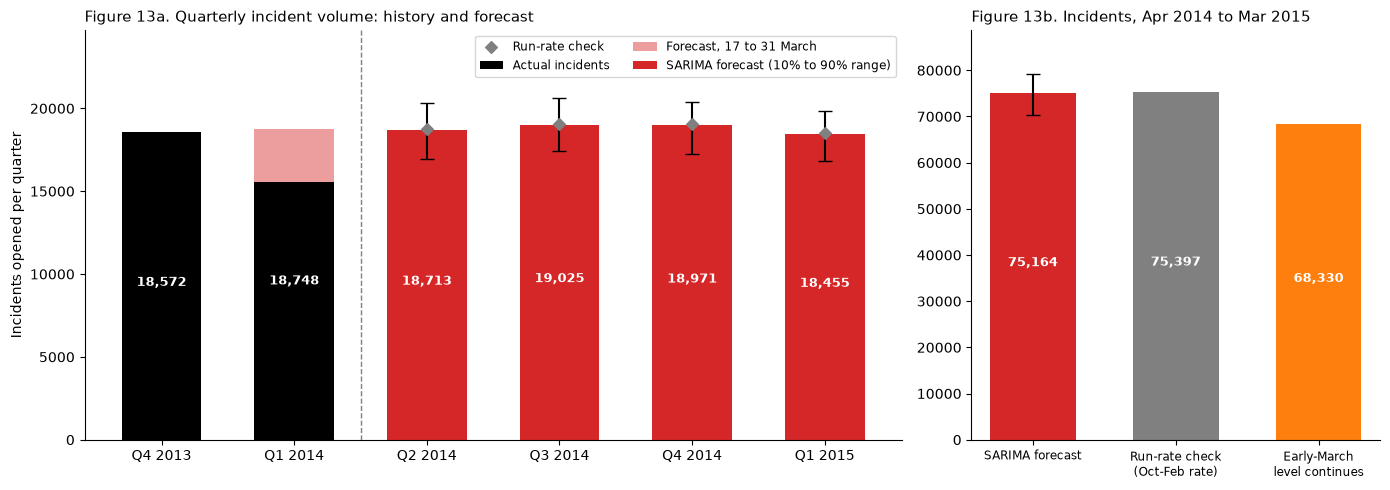

In [32]:
q4_inc = daily_inc.loc["2013-10-01":"2013-12-31"].sum()
q1_inc_actual = daily_inc.loc["2014-01-01":].sum()
q1_inc_rest = inc_point.loc[:"2014-03-31"].sum()
mar_inc = daily_inc.loc["2014-03-01":]
inc_march_rate = mar_inc[mar_inc.index.day_of_week < 5].mean()
fc_i, lo_i, hi_i = inc_annual.iloc[0][["Forecast", "Low (10%)", "High (90%)"]]
inc_totals = pd.Series({"SARIMA forecast": fc_i,
                        "Run-rate check\n(Oct-Feb rate)": inc_annual["Run-rate check"].iloc[0],
                        "Early-March\nlevel continues": inc_march_rate * year_weekdays})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2.4, 1.2]})
x = np.arange(2 + len(inc_quarters))
totals_q = [q4_inc, q1_inc_actual + q1_inc_rest] + list(inc_quarters["Forecast"])
ax1.bar(x[:2], [q4_inc, q1_inc_actual], color="black", width=0.6, label="Actual incidents")
ax1.bar(x[1], q1_inc_rest, bottom=q1_inc_actual, color="tab:red", alpha=0.45, width=0.6, label="Forecast, 17 to 31 March")
ax1.bar(x[2:], inc_quarters["Forecast"], color="tab:red", width=0.6,
        yerr=[inc_quarters["Forecast"] - inc_quarters["Low (10%)"], inc_quarters["High (90%)"] - inc_quarters["Forecast"]],
        capsize=5, label="SARIMA forecast (10% to 90% range)")
ax1.scatter(x[2:], inc_quarters["Run-rate check"], color="grey", marker="D", zorder=3, label="Run-rate check")
for k, v in enumerate(totals_q):
    ax1.text(k, v * 0.5, f"{v:,.0f}", ha="center", color="white", fontsize=9, fontweight="bold")
ax1.set_ylim(0, max(inc_quarters["High (90%)"].max(), max(totals_q)) * 1.2)
ax1.axvline(1.5, color="grey", linestyle="--", linewidth=1)
ax1.set_xticks(x)
ax1.set_xticklabels(["Q4 2013", "Q1 2014"] + list(inc_quarters.index))
ax1.set_ylabel("Incidents opened per quarter")
ax1.set_title("Figure 13a. Quarterly incident volume: history and forecast", loc="left", fontsize=11)
ax1.legend(loc="upper right", fontsize=8.5, ncol=2)

ax2.bar(range(3), inc_totals.values, color=["tab:red", "grey", "tab:orange"], width=0.6)
ax2.errorbar(0, fc_i, yerr=[[fc_i - lo_i], [hi_i - fc_i]], color="black", capsize=5)
for k, v in enumerate(inc_totals.values):
    ax2.text(k, v * 0.5, f"{v:,.0f}", ha="center", color="white", fontsize=9, fontweight="bold")
ax2.set_xticks(range(3))
ax2.set_xticklabels(inc_totals.index, fontsize=8.5)
ax2.set_ylim(0, hi_i * 1.12)
ax2.set_title("Figure 13b. Incidents, Apr 2014 to Mar 2015", loc="left", fontsize=11)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/track2_incident_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `q4_inc / q1_inc_actual / q1_inc_rest` : Actual incidents in Q4 2013, actual incidents 1 January to 16 March, and the forecast for 17 to 31 March.
- `inc_march_rate = mar_inc[weekdays].mean()` : Incidents per weekday in early March, for the 'level continues' scenario.
- `inc_totals = pd.Series({...})` : The three 12-month totals in Figure 13b; year_weekdays comes from section 16b.
- `ax1.bar(...); ax1.bar(..., bottom=q1_inc_actual)` : Actual quarters in black; the forecast part of Q1 2014 stacked in light red.
- `ax1.bar(x[2:], ..., yerr=[...])` : Forecast quarters with error bars from the 10% to the 90% simulated total.
- `ax1.scatter(..., marker="D")` : Run-rate check as grey diamonds.
- `ax2.bar(...); ax2.errorbar(...)` : The three annual incident totals; the error bar shows the model's range.
- `fig.savefig("../reports/figures/track2_incident_forecast.png", ...)` : Saves the figure for the report.

</details>

**Result.** Figure 13a: the forecast quarters (18,455 to 19,025) sit level with the actual Q4 2013 (18,572, which included Christmas) and with Q1 2014 (18,748: actual to 16 March plus the forecast for the rest of March); the run-rate diamonds sit at or just above each bar. As for all tickets, the quarters differ only by their number of weekdays, and the model has no Christmas dip, so Q4 2014 is likely overstated by about 6%. Figure 13b: 75,164 incidents over the next 12 months, with the run-rate check at 75,397 and the early-March scenario at about 68,300, below the error bar.

## 19. Final conclusion

The daily ticket series (all tickets; 1 October 2013 to 16 March 2014, 167 days, 42,304 tickets; Table 3b) contains:

- A very strong **weekly cycle**: about 300 to 410 tickets on weekdays and 4 to 9 at weekends (Table 5a; seasonal strength 0.95, Table 5b; Figures 2 and 3).
- **No clear trend** from October to February, a **Christmas dip** in late December, and a level about **15% lower** in early March (Figure 1b; Table 5c-2).
- No within-month pattern (Table 5c-1), and too little history (5.5 months) to estimate a yearly pattern.

The original series is non-stationary (ADF p = 0.18, Table 6b). One regular difference makes it stationary (p < 0.001, Table 6c), and so does a weekly difference alone (p = 0.0001, Table 6d-1), so ARIMA uses d = 1, and SARIMA uses D = 1 with s = 7 and no regular difference (Tables 6e and 7). No log transformation is used, because the weekly swing does not grow with the level of the series (unlike AirPassengers).

ARIMA(1, 1, 3) is a useful baseline, but it has no seasonal part: it forecasts close to the weekday level every day and over-forecasts every weekend (WAPE 54.8%; Table 12, Figure 7b). Holt-Winters did worse than repeating last week (WAPE 26.5% against 21.5%). SARIMA models the 7-day cycle explicitly and was the best model on the test period on every measure: WAPE 11.1%, MAE 26.7 and RMSE 39.4 tickets a day, weekday MAPE 10.7% and weekly-total MAPE 9.1% (Tables 12, 12b-1 and 12b-2; Figure 8). Its residuals show no significant leftover pattern (Ljung-Box p = 0.18 and 0.17, Table 10b; one correlogram bar at lag 6 just outside the band, Figure 6), but they are heavy-tailed because of the holidays (Jarque-Bera p < 0.001, Table 10c; Figure 6), so its forecast ranges are too narrow.

### Final model

**SARIMA(1, 0, 0)x(1, 1, 1, 7)**, trained on all 167 days (Table 15a-1, Figure 10) and used to forecast every day from 17 March 2014 to 31 March 2015 (Tables 15b-1 and 15b-2; Figures 11 and 12).

| Period | SARIMA forecast | 10% to 90% range | Run-rate check |
|---|---|---|---|
| Q2 2014 | 23,181 | 21,328 to 25,132 | 23,331 |
| Q3 2014 | 23,569 | 21,674 to 25,447 | 23,690 |
| Q4 2014 | 23,506 | 21,558 to 25,333 | 23,690 |
| Q1 2015 | 22,859 | 21,070 to 24,536 | 22,972 |
| **Next 12 months (Apr 2014 to Mar 2015)** | **93,115** | **88,036 to 98,113** | **93,683** |

The selection rests on one test period. On the rolling 4-week backtest (Table 17a, 12 origins), no model reliably beat repeating last week, the run-rate had the lowest error on 4-week totals (15.5% against 17.7% for SARIMA), and the models' 80% ranges contained the actual total only half of the time. SARIMA and the run-rate agree within 1% on every quarter, so the planning figure below uses the simpler run-rate, with the SARIMA forecast as its model-based confirmation.

### Planning estimate for management
**Incident volume (Objective 2 as worded, section 18):** about 18,500 to 19,100 incidents per quarter and about 75,000 over the next 12 months. The SARIMA incident forecast (75,164, 10% to 90% range 70,670 to 79,491) and the run-rate (75,397, about 289 incidents per weekday) agree within 0.5% (Tables 18a, 18e and 18f; Figure 13). Early March ran about 9% lower; if that continues, about 16,800 to 17,300 per quarter and about 68,000 over 12 months (Figure 13b). Allow about ±10%: the run-rate's error on 4-week incident totals in ordinary weeks was 9.3% on average and at most 15.2% (Table 18c). Expect December to be about 19% below the other months (Table 18a). Split by field (Table 18g): applications about 67% of incidents, subapplications about 18%, computers about 9%.

**All tickets** (incidents, requests for information and complaints; the workload the desk must staff for):
**Planning estimate:** about 23,000 to 23,700 tickets per quarter and about 94,000 over the next 12 months at the October to February rate (about 359 tickets per weekday; Table 14a). Early March 2014 ran about 15% lower (315 per weekday, Table 5c-2); if that level continues, the figures would be about 20,200 to 20,800 per quarter and about 82,000 over 12 months (Figure 12b). Plan within this range and check it against April's volume as soon as it is available. An earlier, independent exploratory projection that repeated the average volume of each weekday gave about 22,700 for the next quarter and about 90,900 for 2014, in line with this estimate.

**Error to allow:** about ±10%, the run-rate's own error on 4-week totals in ordinary periods (Table 17b: 8.1% on average, at most 11.4%); quarterly accuracy could not be tested with 5.5 months of data. Expect December to be about 18% below the other months (about 6% for the October to December quarter), based on one December (Table 14a). Refresh the estimate monthly.

**Limits**
- Built on five and a half months of history. The models learn only the weekly cycle and the recent level; they cannot know about yearly seasonality, holidays or business changes (the forecast makes December 2014 its busiest month, Table 15b-3).
- No model reliably beats repeating last week: not on rolling 7-day forecasts (Table A1a) and not on rolling 4-week forecasts (Table 17a).
- A validated quarterly and annual forecast needs at least two to three years of complete data and a holiday calendar; with that, a yearly seasonal term and holiday effects could be added to the SARIMA model.

# Appendix A. Short-term evaluation: rolling 7-day forecasts
Not needed for the quarterly and annual objective. Kept as supporting evidence that no model reliably beats repeating last week, and for one nuance: Holt-Winters is slightly more accurate day by day, so it would suit a short-term daily staffing forecast.

## A1. Rolling 7-day forecasts and the rule set in advance
At each origin day the models see only the past and forecast the next 7 days. Two baselines (repeat last week, mean of the same weekday over 4 weeks) and Holt-Winters with weekly seasonality (plain and with a damped trend). `run_eval` makes the rolling forecasts; `score` reports daily MAE, RMSE, weekday MAPE, WAPE, bias and the error on each week's total.

**Rule set in advance:** a model counts as better only if its daily WAPE is at least 10% lower than both baselines and its weekly-total error is also lower.

In [33]:
H = 7   # forecast horizon in days

def repeat_last_week(hist):
    return hist.iloc[-7:].to_numpy(dtype=float)

def weekday_mean_4w(hist):
    return hist.iloc[-28:].to_numpy(dtype=float).reshape(4, 7).mean(axis=0)

def holt_winters(hist):
    m = ExponentialSmoothing(hist.astype(float), trend=None, seasonal="add",
                             seasonal_periods=7, initialization_method="estimated").fit()
    return m.forecast(H).to_numpy()

def holt_winters_damped(hist):
    m = ExponentialSmoothing(hist.astype(float), trend="add", damped_trend=True, seasonal="add",
                             seasonal_periods=7, initialization_method="estimated").fit()
    return m.forecast(H).to_numpy()

models = {"Repeat last week": repeat_last_week,
          "Weekday mean, 4 weeks": weekday_mean_4w,
          "Holt-Winters": holt_winters,
          "Holt-Winters, damped trend": holt_winters_damped}

def run_eval(models_, origins_):
    """Rolling-origin forecasts: at each origin day, forecast the next H days from the history up to that day."""
    parts = []
    for t in origins_:
        hist = daily.loc[:t]
        actual = daily.loc[t + pd.Timedelta(days=1): t + pd.Timedelta(days=H)].to_numpy()
        for name, f in models_.items():
            fc = np.clip(f(hist), 0, None)
            parts.append(pd.DataFrame({"model": name, "origin": t, "h": np.arange(1, H + 1),
                                       "actual": actual, "fc": fc}))
    r = pd.concat(parts, ignore_index=True)
    r["date"] = r["origin"] + pd.to_timedelta(r["h"], unit="D")      # calendar date of each forecast day
    r["abs_err"] = (r["actual"] - r["fc"]).abs()
    r["sq_err"] = (r["actual"] - r["fc"]) ** 2
    return r

def score(r):
    g = r.groupby("model")
    wdm = (r["date"].dt.day_of_week < 5) & (r["actual"] > 0)          # weekdays with at least one ticket
    day_ape = (r.loc[wdm, "abs_err"] / r.loc[wdm, "actual"] * 100).groupby(r.loc[wdm, "model"]).mean()
    out = pd.DataFrame({"MAE": g["abs_err"].mean(),
                        "RMSE": np.sqrt(g["sq_err"].mean()),
                        "MAPE % (weekdays)": day_ape,
                        "WAPE %": g["abs_err"].sum() / g["actual"].sum() * 100,
                        "bias": (g["fc"].sum() - g["actual"].sum()) / g["actual"].count()})
    wk = r.groupby(["model", "origin"]).agg(actual=("actual", "sum"), fc=("fc", "sum"))
    wk["ape"] = (wk["fc"] - wk["actual"]).abs() / wk["actual"] * 100
    out["weekly-total error %"] = wk.groupby("model")["ape"].mean()
    return out.round(2)

<details>
<summary><b>Code notes, line by line</b></summary>

- `H = 7` : Forecast horizon: 7 days.
- `def repeat_last_week(hist):` : Baseline 1: the last 7 days repeated.
- `def weekday_mean_4w(hist):` : Baseline 2: average of the same weekday over the last 4 weeks (reshape to 4 x 7, mean per column).
- `def holt_winters(hist):` : Holt-Winters with weekly season, no trend.
- `def holt_winters_damped(hist):` : Holt-Winters with weekly season and damped trend.
- `models = {...}` : The four short-term methods.
- `def run_eval(models_, origins_):` : At each origin, every model forecasts the next 7 days from the past only.
- `pd.DataFrame({"model", "origin", "h", "actual", "fc"})` : One row per forecast day; h = days ahead.
- `r["date"] = r["origin"] + pd.to_timedelta(r["h"], unit="D")` : Calendar date of each forecast day (to find weekdays).
- `r["abs_err"], r["sq_err"]` : Absolute and squared daily errors.
- `def score(r):` : Summary per model.
- `"MAE", "RMSE"` : Average miss and root mean squared miss, tickets per day.
- `"MAPE % (weekdays)": weekdays with at least one ticket` : Average % error on weekdays; New Year's Day (0 tickets) is skipped because % error is undefined there.
- `"WAPE %", "bias"` : Total error share, and average over- (+) or under- (-) forecast per day.
- `wk = r.groupby(["model", "origin"]).agg(...); wk["ape"]` : Each 7-day total's % error, averaged per model.

</details>

Origins run from 31 January to 9 March 2014: 38 origins, 266 forecasts per model.

In [34]:
first = pd.Timestamp(TEST_START) - pd.Timedelta(days=1)
last = daily.index[-1] - pd.Timedelta(days=H)
origins = daily.index[(daily.index >= first) & (daily.index <= last)]
print(len(origins), origins[0].date(), origins[-1].date())
res = run_eval(models, origins)

38 2014-01-31 2014-03-09


<details>
<summary><b>Code notes, line by line</b></summary>

- `first = TEST_START - 1 day; last = last day - H` : Origins from 31 January, leaving 7 days after the last one.
- `origins = daily.index[(>= first) & (<= last)]` : The 38 origins.
- `res = run_eval(models, origins)` : Rolling 7-day forecasts.

</details>

In [35]:
print("Table A1a. Rolling 7-day forecasts, test origins")
display(score(res))
print("Table A1b. Mean absolute error by days ahead (tickets)")
display(res.pivot_table(index="h", columns="model", values="abs_err", aggfunc="mean").round(1))

Table A1a. Rolling 7-day forecasts, test origins


,MAE,RMSE,MAPE % (weekdays),WAPE %,bias,weekly-total error %
model,,,,,,
Holt-Winters,30.65,41.25,10.83,12.31,13.01,8.15
"Holt-Winters, damped trend",30.58,41.16,10.79,12.28,13.19,8.12
Repeat last week,31.36,44.39,12.78,12.59,12.44,7.99
"Weekday mean, 4 weeks",33.22,46.06,13.73,13.34,22.66,11.79


Table A1b. Mean absolute error by days ahead (tickets)


model,Holt-Winters,"Holt-Winters, damped trend",Repeat last week,"Weekday mean, 4 weeks"
h,,,,
1,30.8,30.8,30.8,33.8
2,32.0,31.9,31.5,33.6
3,33.0,32.8,31.9,33.9
4,30.6,30.4,32.3,34.0
5,31.2,31.2,31.6,33.6
6,28.4,28.4,31.2,32.3
7,28.5,28.5,30.2,31.4


<details>
<summary><b>Code notes, line by line</b></summary>

- `display(score(res))` : Table A1a: all measures per model.
- `res.pivot_table(index="h", columns="model", values="abs_err", aggfunc="mean")` : Table A1b: MAE by days ahead.

</details>

**Result.** No model met the rule on the test origins (Table A1a): repeat last week 12.59% daily WAPE and 7.99% weekly-total error; Holt-Winters 12.31% and 8.15%; Holt-Winters with damped trend 12.28% and 8.12%; 4-week weekday mean 13.34% and 11.79%. Holt-Winters gains mainly at 4 to 7 days ahead (MAE 28.4 to 31.2 against 30.2 to 32.3 for repeat last week, Table A1b). The 38 origins overlap, so there are about 6 independent weeks of evidence.

Holt-Winters was consistently a little more accurate day by day (also on earlier origins, Table A2: 9.29% against 11.11% without the holiday window), but the gain was too small, and its weekly-total error was not consistently lower, so it did not meet the rule. Repeat last week is kept for its simplicity; Holt-Winters would be a reasonable second choice for a short-term daily staffing forecast.

## A2. The same models on earlier origins
A model that looks better on one period may just have been lucky there. So the four models from A1 are also scored on origins before the test period: forecasts made each day from 1 December 2013 to 24 January 2014, each covering the next 7 days (55 origins, ending before the test period starts). The second table drops the origins from 17 December to 8 January, whose forecasts run into Christmas and New Year, when every model's error jumps (32 origins). If Holt-Winters is really more accurate day by day, it should beat repeat last week in both tables, not only on the test origins.

In [36]:
pre_origins = daily.index[(daily.index >= "2013-12-01") & (daily.index <= "2014-01-24")]
noh = pre_origins[(pre_origins < "2013-12-17") | (pre_origins > "2014-01-08")]
for label, o_ in [("Earlier origins, 1 Dec to 24 Jan", pre_origins),
                  ("Earlier origins without the holiday window", noh)]:
    print(f"Table A2. {label} ({len(o_)} origins)")
    display(score(run_eval(models, o_)))

Table A2. Earlier origins, 1 Dec to 24 Jan (55 origins)


,MAE,RMSE,MAPE % (weekdays),WAPE %,bias,weekly-total error %
model,,,,,,
Holt-Winters,50.97,89.61,1300.52,21.90,2.93,22.09
"Holt-Winters, damped trend",52.86,91.90,1321.77,22.71,3.09,23.45
Repeat last week,55.87,104.64,1356.84,24.01,-3.71,23.76
"Weekday mean, 4 weeks",61.58,101.34,1397.28,26.46,1.36,29.85


Table A2. Earlier origins without the holiday window (32 origins)


,MAE,RMSE,MAPE % (weekdays),WAPE %,bias,weekly-total error %
model,,,,,,
Holt-Winters,24.28,33.73,7.98,9.29,-0.87,5.40
"Holt-Winters, damped trend",25.13,34.48,8.52,9.61,1.60,6.41
Repeat last week,29.04,40.45,10.01,11.11,-3.13,5.26
"Weekday mean, 4 weeks",43.30,66.97,15.56,16.56,-21.76,15.24


<details>
<summary><b>Code notes, line by line</b></summary>

- `pre_origins = daily.index[1 Dec to 24 Jan]` : Origins before the test period.
- `noh = pre_origins outside 17 Dec to 8 Jan` : The same without forecasts that run into the holidays.
- `for label, o_ in [...]: display(score(run_eval(models, o_)))` : Table A2 for both sets.

</details>

**Result.** Holt-Winters is a little more accurate day by day than repeating last week: 12.31% against 12.59% daily WAPE on the test origins, 21.90% against 24.01% on earlier origins, and 9.29% against 11.11% on earlier origins without the holiday window. It is not better on weekly totals (8.15% against 7.99% on the test origins), so it does not meet the rule set in advance and is not used for quarterly planning. For a short-term daily staffing forecast, it would be a reasonable choice. Weekday MAPE (added with RMSE) is only meaningful without the holiday window: Christmas Day and the days around it had only a handful of tickets, so the first Table A2 shows weekday MAPE in the hundreds or thousands of percent.